In [1]:

import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import astropy.units as u
from astropy.timeseries import LombScargle
from scipy.ndimage import median_filter
from pathlib import Path
from scipy.optimize import minimize_scalar, least_squares
from scipy.signal import find_peaks
from astropy.table import Table

C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
# ======================= PARÁMETROS CONFIGURABLES =======================

TIC = "TIC 117831881"

SECTORES = ["TESS Sector 91", "TESS Sector 92"]

SEED = 42

P_ORB = 1.843799  # d; periodo orbital fisico para TODAS las etapas



# Cadencia preferida [s] si SPOC ofrece varias en el mismo sector (p. ej. 20 s y 120 s)

PREFERIR_EXPTIME_SPOC = 120.0

APLICAR_CROWDSAP_EN_SAP = True  # corrige dilución por vecinos en sap_flux si existe CROWDSAP



# Pipelines a ejecutar secuencialmente

PIPELINES = [

    dict(

        nombre="QLP",

        autores=["QLP"],

        flux_column="sap_flux",

        aplicar_cbv=True,

        cbv_types=["SingleScale", "Spike"],

    ),

    dict(

        nombre="SPOC",

        autores=["SPOC", "TESS-SPOC"],   # usa SPOC 2-min si existe; si no, FFI TESS-SPOC

        flux_column="pdcsap_flux",       # reducción oficial PDC-MAP (NO reaplicar CBV)

        aplicar_cbv=False,

        cbv_types=[],

    ),

    # Descomenta este bloque si también quieres auditar SPOC partiendo desde sap_flux + CBV manual:

    # dict(

    #     nombre="SPOC_SAP_CBV",

    #     autores=["SPOC", "TESS-SPOC"],

    #     flux_column="sap_flux",

    #     aplicar_cbv=True,

    #     cbv_types=["SingleScale", "Spike"],

    # ),

]



# --- 1. Reducción base (dominio del tiempo) ---

VENTANA_DIAS = 0.5            # ventana de la mediana móvil para picos superiores

SIGMA_SUP_TIEMPO = 3.5        # SOLO recorte superior (flares/rayos cósmicos)

GAP_DIAS = 0.4                # salto temporal que define un nuevo segmento/órbita TESS



# --- 2. Periodogramas ---

FMIN, FMAX = 0.05, 24.0       # rango de frecuencias [ciclos/día]

OVERSAMPLE = 10

BIN_MIN = 20                  # binning (min) para acelerar PDM global y su bootstrap

PDM_NBINS = 20

N_BOOT = 100                  # iteraciones bootstrap para FAP de PDM



# --- 3. Periodo y ventanas de fase ---

P_MANUAL = P_ORB               # None = FACTOR_PERIODO * P_LS refinado con PDM fino

FACTOR_PERIODO = 2            # 2 para binarias eclipsantes simétricas/casi-simétricas

REFINAR_PERIODO = True        # afina P con PDM de alta resolución (+-0.5 %)

USAR_P_OC = False             # True: usa P de medir_oc; False: conserva P_PDM fino



PROTEGER_FASE = [(-0.11, 0.11), (0.37, 0.57)]



# --- 4. Análisis por eclipse (O-C) ---

HALF_WIN_FASE = 0.10

SEC_FASE = 0.47

OC_RANGO_D = 0.25

OC_SIGMA = 3.0

OC_MIN_D = 0.004



# --- 5. Detección y corrección por CICLO ORBITAL ---

CORREGIR_OFFSET_CICLO = True

CORREGIR_RAMPA_CICLO = True

MAX_OFFSET_CORREGIBLE = 0.015

SIGMA_RMS_CICLO = 2.5

SIGMA_ECL_CICLO = 2.8

MIN_PUNTOS_OOE_CICLO = 15



# --- 6. Limpieza iterativa en fase ---

FASE_NBINS = 160

K_INF, K_SUP = 2.8, 3.0

K_ECLIPSE_EXTREMO = 5.5

N_ITER = 8


In [3]:
N_ARMONICOS = 20                       # minimo de armonicos en la serie de Fourier
AUTO_EXTENDER_ARMONICOS = True          # incluir todos los armonicos hasta FMAX_EFECTIVA
INCLUIR_SUBARMONICOS = False            # en modelo P, incluir frecuencias semienteras opcionales
N_SUBARMONICOS = 5                     # 0.5, 1.5, ... (N_SUBARMONICOS-0.5)*f_orb
PROBAR_DOBLE_PERIODO = True            # comparar f_orb y f_orb/2 como fundamentales
SELECCION_MODELO = 'bic'               # 'bic', 'P' o '2P'; BIC penaliza exceso de parametros
T0_CONFIG = None                       # BTJD: None => T0 inferido de la curva limpia
REFINAR_F_ORB = True                   # minima cuadrados no lineales con proyeccion variable
VENTANA_REF_F_ORB = 0.0015             # semi-ancho relativo alrededor de frecuencia nominal
N_HARM_REFINAMIENTO = 12              # armonicos usados en refinamiento rapido, sin limitar ajuste final
MAX_PUNTOS_REFINAMIENTO = 15000        # submuestreo proporcional, solo para refinamiento
MODO_ECLIPSES = 'plantilla'            # 'plantilla', 'mascara' o 'fourier'
BINS_PLANTILLA = 240                  # medianas en fase tras restar Fourier
BINS_GRAFICO = 70                      # medianas en grafico de fase
FASES_ECLIPSE = [(-0.11, 0.11), (0.37, 0.57)]  # fase relativa a T0 (P_ORB)
FMIN_RAPIDA = 0.05                    # frecuencia minima periodograma global, c/d
FMAX_RAPIDA = 24.0                    # frecuencia maxima solicitada, c/d
FACTOR_NYQUIST_SEGURO = 0.85          # Nyquist heuristica para cadencia mediana (no exacta con gaps)
OVERSAMPLING_RAPIDO = 10              # resolucion 1/(OVERSAMPLING*T)
FAP_METODO_RAPIDO = 'baluev'          # 'baluev' o 'bootstrap'
N_BOOTSTRAPS_LS = 500                 # si se usa bootstrap; limitado por coste
FAP_UMBRAL_RAPIDO = 0.01
SNR_UMBRAL_RAPIDO = 4.5
CRITERIO_SIGNIFICANCIA = 'ambos'      # 'ambos', 'fap', 'snr'
VENTANA_SNR = 1.0                     # semiancho de banda local, c/d
MAX_SENALES_RAPIDAS = 15
MAX_PICOS_EVALUADOS = 80
TOL_RAYLEIGH = 1.0                     # veto: +/- TOL_RAYLEIGH / T
TOL_MIN_CPD = 0.0                     # opcion de tolerancia adicional en c/d
N_COMBINACIONES = 5                   # detectar f_i +/- n*f_orb
VETAR_ALIAS_VENTANA = True
AMPLITUD_MIN_VENTANA = 0.32           # altura espectral de ventana para considerar aliases
MAX_ALIAS_VENTANA = 8
MAX_F_VENTANA = 2.0                    # buscar aliases a desplazamientos < 2 c/d
MAX_PUNTOS_VENTANA = 4000
PDM_PUNTOS_MAX = 8000
PDM_GRILLA_LOCAL = 180
SALIDA_CORTA = Path('resultados_prewhitening')
GUARDAR_PNG = True
MOSTRAR_GRAFICOS_RAPIDOS = True        # False para ejecucion por lotes


In [4]:
# ======================= 1) DESCARGA Y REDUCCIÓN BASE =======================

def inspeccionar_disponibilidad():

    """Muestra qué autores y cadencias existen en MAST para el objeto en los sectores pedidos."""

    sr_all = lk.search_lightcurve(TIC)

    print("================ DISPONIBILIDAD EN MAST ================")

    if len(sr_all) == 0:

        print(f"No se encontraron curvas para {TIC} en MAST.")

        print("========================================================\n")

        return sr_all



    sr_sec = sr_all[np.isin(sr_all.mission, SECTORES)]

    if len(sr_sec) == 0:

        print(f"No se encontraron curvas para {TIC} en {SECTORES}.")

        print("Productos disponibles en otros sectores:")

        print(sr_all)

    else:

        print(sr_sec)

    print("========================================================\n")

    return sr_sec





def _seleccionar_una_cadencia_por_sector(sr, exptime_pref=PREFERIR_EXPTIME_SPOC):

    """Evita descargar cadencias duplicadas (ej. 20 s y 120 s) dentro de un mismo sector."""

    idx_keep = []

    misiones = np.asarray(sr.mission)

    exptimes = np.asarray(sr.exptime.value, dtype=float)

    for sec in SECTORES:

        cand = np.where(misiones == sec)[0]

        if len(cand) == 0:

            continue

        if len(cand) == 1:

            idx_keep.append(int(cand[0]))

        else:

            mejor = cand[np.argmin(np.abs(exptimes[cand] - exptime_pref))]

            idx_keep.append(int(mejor))

    return sr[idx_keep]





def descargar_pipeline(cfg):

    """Descarga las curvas del primer autor disponible dentro de cfg['autores']."""

    nombre = cfg["nombre"]

    flux_col = cfg["flux_column"]

    for autor in cfg["autores"]:

        sr = lk.search_lightcurve(TIC, author=autor)

        if len(sr) == 0:

            print(f"[{nombre}] Sin resultados en MAST para author='{autor}'.")

            continue



        sr = sr[np.isin(sr.mission, SECTORES)]

        if len(sr) == 0:

            print(f"[{nombre}] author='{autor}' existe en otros sectores, pero no en {SECTORES}.")

            continue



        sr = _seleccionar_una_cadencia_por_sector(sr)

        print(f"[{nombre}] Autor seleccionado: {autor} | columna: {flux_col}")

        print(sr)

        try:

            lcs = sr.download_all(quality_bitmask="hard", flux_column=flux_col)

            return lcs, autor, flux_col

        except Exception as e:

            print(f"[{nombre}] Falló descarga con '{flux_col}' ({type(e).__name__}: {e}). "

                  f"Reintentando con 'sap_flux'...")

            lcs = sr.download_all(quality_bitmask="hard", flux_column="sap_flux")

            return lcs, autor, "sap_flux"



    print(f"[{nombre}] AVISO: No se encontraron datos para autores {cfg['autores']} en {SECTORES}.")

    return None, None, None





def corregir_dilucion_crowdsap(lc):

    """

    Replica la corrección de dilución de SPOC PDC-MAP sobre sap_flux cuando CROWDSAP está disponible:

      F_corr = F - (1 - CROWDSAP) * F_continuo

    Restaura la profundidad real de los eclipses ante contaminación por estrellas vecinas.

    """

    crowd = lc.meta.get("CROWDSAP", None)

    if crowd is None or not np.isfinite(crowd) or not (0.0 < float(crowd) < 1.0):

        return lc

    crowd = float(crowd)

    f = np.asarray(lc.flux.value, dtype=np.float64)

    f_cont = np.nanpercentile(f, 70)

    f_corr = f - (1.0 - crowd) * f_cont

    lc_out = lc.copy()

    lc_out.flux = f_corr * lc.flux.unit

    print(f"  S{lc.meta.get('SECTOR')}: corrección de dilución aplicada (CROWDSAP={crowd:.4f})")

    return lc_out





def cotrending_cbv(lc, cbv_types):

    """Aplica CBVCorrector solo cuando se trabaja desde sap_flux (nunca sobre pdcsap_flux)."""

    if not cbv_types:

        return lc

    cbv_indices = [np.arange(1, 9) if ct != "Spike" else "ALL" for ct in cbv_types]

    try:

        cbvc = lk.correctors.CBVCorrector(lc)

        cbvc.correct(cbv_type=cbv_types, cbv_indices=cbv_indices)

        print(f"  S{lc.meta.get('SECTOR')}: CBV aplicado ({', '.join(cbv_types)})")

        return cbvc.corrected_lc

    except Exception as e:

        print(f"  S{lc.meta.get('SECTOR')}: CBV no aplicado ({type(e).__name__}: {e})")

        return lc





def clip_superior_y_nivelar_segmentos(lc):

    """

    1) Nivela cada órbita de TESS con su percentil 70 (inmune a eclipses).

    2) Recorta SOLO picos superiores por segmento (separados por GAP_DIAS).

    """

    t = np.asarray(lc.time.value, dtype=np.float64)

    f = np.asarray(lc.flux.value, dtype=np.float64)

    dt = np.nanmedian(np.diff(t))

    n = max(3, int(VENTANA_DIAS / dt) | 1)



    cortes = np.where(np.diff(t) > GAP_DIAS)[0] + 1

    ini = np.r_[0, cortes]

    fin = np.r_[cortes, len(t)]



    tend = np.empty_like(f)

    f_niv = np.empty_like(f)

    escala_seg = np.empty_like(f)

    for a, b in zip(ini, fin):

        seg = f[a:b]

        nivel_seg = np.nanpercentile(seg, 70)

        seg_norm = seg / nivel_seg

        f_niv[a:b] = seg_norm

        escala_seg[a:b] = nivel_seg

        tend[a:b] = median_filter(seg_norm, size=min(n, (b - a) | 1), mode="nearest")



    resid = f_niv - tend

    sig = 1.4826 * np.nanmedian(np.abs(resid - np.nanmedian(resid)))

    buenos = resid < SIGMA_SUP_TIEMPO * sig

    print(f"  S{lc.meta.get('SECTOR')}: {len(ini)} segmentos/órbitas | dt~{dt*1440:.1f} min | "

          f"picos superiores removidos: {(~buenos).sum()} de {len(lc)}")



    lc_out = lc[buenos].copy()

    lc_out.flux = f_niv[buenos] * u.dimensionless_unscaled

    if lc_out.flux_err is not None:

        err_val = np.asarray(lc.flux_err.value, dtype=np.float64)[buenos]

        lc_out.flux_err = (err_val / escala_seg[buenos]) * u.dimensionless_unscaled

    return lc_out





def reducir_base(lc, aplicar_cbv, cbv_types, es_pdcsap):

    lc = lc.remove_nans()

    if hasattr(lc, "quality") and lc.quality is not None:

        lc = lc[lc.quality == 0]

    if es_pdcsap:

        print(f"  S{lc.meta.get('SECTOR')}: usando pdcsap_flux oficial de SPOC (sin doble CBV)")

    else:

        lc = cotrending_cbv(lc, cbv_types).remove_nans()

        if APLICAR_CROWDSAP_EN_SAP:

            lc = corregir_dilucion_crowdsap(lc)

    lc = clip_superior_y_nivelar_segmentos(lc)

    return lc


In [5]:
# ======================= 2) PERIODOGRAMAS =======================

def bin_tiempo(t, y, minutos):

    w = minutos / 1440.0

    k = np.floor((t - t.min()) / w).astype(int)

    cnt = np.bincount(k)

    ok = cnt > 0

    tb = np.bincount(k, weights=t)[ok] / cnt[ok]

    yb = np.bincount(k, weights=y)[ok] / cnt[ok]

    return tb, yb





def pdm_theta(t, y, freqs, nbins=PDM_NBINS):

    var = np.var(y, ddof=1)

    theta = np.empty(len(freqs))

    for i, f in enumerate(freqs):

        idx = (((t * f) % 1.0) * nbins).astype(int)

        cnt = np.bincount(idx, minlength=nbins)

        s1 = np.bincount(idx, weights=y, minlength=nbins)

        s2 = np.bincount(idx, weights=y * y, minlength=nbins)

        ok = cnt > 1

        ss = (s2[ok] - s1[ok] ** 2 / cnt[ok]).sum()

        dof = (cnt[ok] - 1).sum()

        theta[i] = (ss / dof) / var

    return theta





def analizar(t, y, titulo):

    baseline = t.max() - t.min()

    freq = np.arange(FMIN, FMAX, 1.0 / (OVERSAMPLE * baseline))



    ls = LombScargle(t, y)

    power = ls.power(freq)

    i_ls = np.argmax(power)

    P_ls = 1.0 / freq[i_ls]

    fap_ls = ls.false_alarm_probability(power[i_ls], minimum_frequency=FMIN,

                                        maximum_frequency=FMAX, method="baluev")

    niveles = ls.false_alarm_level([0.01, 0.001], minimum_frequency=FMIN,

                                   maximum_frequency=FMAX, method="baluev")



    tb, yb = bin_tiempo(t, y, BIN_MIN)

    theta = pdm_theta(tb, yb, freq)

    i_pdm = np.argmin(theta)

    P_pdm = 1.0 / freq[i_pdm]

    rng = np.random.default_rng(SEED)

    min_boot = np.array([pdm_theta(tb, rng.permutation(yb), freq).min() for _ in range(N_BOOT)])

    fap_pdm = (np.sum(min_boot <= theta[i_pdm]) + 1) / (N_BOOT + 1)



    print(f"\n[{titulo}] N={len(t)}, baseline={baseline:.2f} d")

    print(f"  LS : P = {P_ls:.6f} d (2xP = {2*P_ls:.6f} d), potencia = {power[i_ls]:.4f}, FAP = {fap_ls:.2e}")

    print(f"  PDM: P = {P_pdm:.6f} d (2xP = {2*P_pdm:.6f} d), theta_min = {theta[i_pdm]:.4f}, FAP ~ {fap_pdm:.3f}"

          f" (mínimo resoluble 1/{N_BOOT + 1})")



    fig, axs = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)

    axs[0].plot(freq, power, lw=0.7)

    for nv, lab in zip(niveles, ["FAP 1%", "FAP 0.1%"]):

        axs[0].axhline(nv, ls="--", lw=0.8, label=lab)

    axs[0].axvline(1 / P_ls, c="r", alpha=0.4)

    axs[0].set(ylabel="Potencia LS", title=f"{titulo} | LS: P={P_ls:.5f} d, FAP={fap_ls:.1e}")

    axs[0].legend(loc="upper right")



    axs[1].plot(freq, theta, lw=0.7)

    axs[1].axhline(np.percentile(min_boot, 1), ls="--", lw=0.8, label="1er percentil bootstrap")

    axs[1].axvline(1 / P_pdm, c="r", alpha=0.4)

    axs[1].set(xlabel="Frecuencia [ciclos/día]", ylabel=r"$\Theta$ (PDM)",

               title=f"PDM: P={P_pdm:.5f} d, FAP~{fap_pdm:.3f}")

    axs[1].legend(loc="lower right")

    plt.tight_layout()

    plt.show()

    return dict(P_ls=P_ls, P_pdm=P_pdm, fap_ls=fap_ls, fap_pdm=fap_pdm)





def refinar_periodo(t, y, P0, frac=0.005, n=2000):

    freqs = (1.0 / P0) * (1 + np.linspace(-frac, frac, n))

    th = pdm_theta(t, y, freqs, nbins=80)

    return 1.0 / freqs[np.argmin(th)]


In [8]:
# ======================= 3) FUNCIONES DE FASE Y PLANTILLA =======================

def fase(t, P, t0):

    return ((t - t0) / P + 0.25) % 1.0 - 0.25





def mascara_protegida(ph):

    prot = np.zeros(len(ph), dtype=bool)

    for a, b in PROTEGER_FASE:

        prot |= (ph >= a) & (ph <= b)

    return prot





def plantilla(ph, y, nb=FASE_NBINS):

    idx = np.clip(((ph + 0.25) * nb).astype(int), 0, nb - 1)

    med = np.full(nb, np.nan)

    sig = np.full(nb, np.nan)

    for k in range(nb):

        v = y[idx == k]

        if len(v) >= 4:

            m = np.median(v)

            med[k] = m

            sig[k] = 1.4826 * np.median(np.abs(v - m))

    cen = (np.arange(nb) + 0.5) / nb - 0.25

    return cen, med, sig





def interp_periodica(ph, cen, valores):

    ok = np.isfinite(valores)

    c = np.r_[cen[ok] - 1.0, cen[ok], cen[ok] + 1.0]

    v = np.tile(valores[ok], 3)

    return np.interp(ph, c, v)





def epoca_minimo(t, y, P):

    tref = t[0]

    cen, med, _ = plantilla(fase(t, P, tref), y, FASE_NBINS)

    i_min = np.nanargmin(med)

    return tref + cen[i_min] * P


In [6]:
# ======================= 4) O-C POR ECLIPSE =======================

def _plantilla_dt(xs, ys, W, nb=80):

    ok = np.abs(xs) <= W

    xs, ys = xs[ok], ys[ok]

    edges = np.linspace(-W, W, nb + 1)

    cen = 0.5 * (edges[:-1] + edges[1:])

    idx = np.clip(np.digitize(xs, edges) - 1, 0, nb - 1)

    med = np.array([np.median(ys[idx == k]) if np.any(idx == k) else np.nan for k in range(nb)])

    g = np.isfinite(med)

    return lambda x: np.interp(x, cen[g], med[g])





def medir_oc(t, y, P, t0):

    W = HALF_WIN_FASE * P

    dtc = np.nanmedian(np.diff(t))

    ev = []

    for tipo, f0 in ((0, 0.0), (1, SEC_FASE)):

        tc0 = t0 + f0 * P

        n_ini = int(np.floor((t.min() - tc0) / P)) - 1

        n_fin = int(np.ceil((t.max() - tc0) / P)) + 2

        for n in range(n_ini, n_fin):

            tc = tc0 + n * P

            m = np.abs(t - tc) <= W

            if m.sum() >= 0.75 * (2 * W / dtc):

                ev.append((tipo, n, tc, m))

    if len(ev) < 6:

        print("Pocos eclipses completos para O-C; se omite este paso.")

        return dict(P=P, t0=t0, perr=np.nan, malos=np.zeros(len(t), dtype=bool), T=None)



    tipo = np.array([e[0] for e in ev])

    nn = np.array([e[1] for e in ev], dtype=float)

    tcs = np.array([e[2] for e in ev])

    shifts = np.zeros(len(ev))

    grueso = np.linspace(-OC_RANGO_D, OC_RANGO_D, 241)

    fino = np.linspace(-0.003, 0.003, 61)



    for _ in range(3):

        tpl = {}

        for tp in (0, 1):

            if np.any(tipo == tp):

                xs = np.concatenate([t[e[3]] - e[2] - s for e, s in zip(ev, shifts) if e[0] == tp])

                ys = np.concatenate([y[e[3]] for e in ev if e[0] == tp])

                tpl[tp] = _plantilla_dt(xs, ys, W)

        for k, (tp, n, tc, m) in enumerate(ev):

            f, tm, ym = tpl[tp], t[m], y[m]

            sse = [np.sum((ym - f(tm - tc - s)) ** 2) for s in grueso]

            s0 = grueso[int(np.argmin(sse))]

            sse2 = [np.sum((ym - f(tm - tc - (s0 + d))) ** 2) for d in fino]

            shifts[k] = s0 + fino[int(np.argmin(sse2))]



    T = tcs + shifts

    A = np.c_[(tipo == 0).astype(float), (tipo == 1).astype(float), nn]

    pesos = np.where(tipo == 0, 1.0, 0.5)

    buenos = np.ones(len(T), dtype=bool)

    for _ in range(6):

        Aw = A[buenos] * pesos[buenos, None]

        Tw = T[buenos] * pesos[buenos]

        coef = np.linalg.lstsq(Aw, Tw, rcond=None)[0]

        oc = T - A @ coef

        sig = 1.4826 * np.median(np.abs(oc[buenos] - np.median(oc[buenos])))

        nuevo = np.abs(oc) <= OC_SIGMA * max(sig, OC_MIN_D)

        if np.array_equal(nuevo, buenos):

            break

        buenos = nuevo



    sig_fit = np.std(oc[buenos], ddof=min(3, buenos.sum() - 1))

    cov = sig_fit ** 2 * np.linalg.pinv(A[buenos].T @ A[buenos])

    P_new, perr = coef[2], float(np.sqrt(cov[2, 2]))



    print(f"\nO-C: {len(T)} eclipses medidos ({(tipo == 0).sum()} primarios, {(tipo == 1).sum()} secundarios), "

          f"{(~buenos).sum()} discrepantes")

    print(f"  P_OC = {P_new:.6f} +- {perr:.6f} d   (P_PDM fino: {P:.6f} d)")

    print(f"  dispersión del O-C (buenos) = {sig_fit * 1440:.1f} min")

    for k in np.where(~buenos)[0]:

        print(f"  descartado por O-C: {'primario' if tipo[k] == 0 else 'secundario'} "

              f"BTJD {T[k]:.3f}, O-C = {oc[k] * 1440:+.1f} min")



    malos = np.zeros(len(t), dtype=bool)

    for k in np.where(~buenos)[0]:

        malos |= ev[k][3]

    return dict(P=P_new, t0=coef[0], perr=perr, malos=malos, T=T, oc=oc, tipo=tipo, buenos=buenos)





def graf_oc(res, reducidas, etiqueta):

    if res["T"] is None:

        return

    fig, ax = plt.subplots(figsize=(11, 3.6))

    for tp, mk, nom, col in ((0, "o", "Primario", "C0"), (1, "s", "Secundario", "C2")):

        s = res["tipo"] == tp

        b = s & res["buenos"]

        ax.plot(res["T"][b], res["oc"][b] * 1440, mk, c=col, label=nom)

        if np.any(s & ~res["buenos"]):

            ax.plot(res["T"][s & ~res["buenos"]], res["oc"][s & ~res["buenos"]] * 1440, mk,

                    c="r", mfc="none", ms=10, lw=1.5, label=f"{nom} descartado")

    for l in reducidas:

        ax.axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")

    ax.axhline(0, c="k", lw=0.6)

    ax.set(xlabel="BTJD", ylabel="O-C [min]",

           title=f"[{etiqueta}] O-C por eclipse (franjas grises = sectores)")

    ax.legend(ncol=2)

    plt.tight_layout()

    plt.show()


In [7]:
# ======================= 5) DETECCIÓN Y NIVELACIÓN POR CICLO ORBITAL =======================

def procesar_por_ciclos(t, y, P, t0):

    y_corr = y.copy()

    ph = fase(t, P, t0)

    prot = mascara_protegida(ph)

    ooe = ~prot



    ciclo_id = np.floor((t - t0) / P + 0.25).astype(int)

    ciclos_unicos = np.unique(ciclo_id)



    cen0, med0, _ = plantilla(ph, y_corr, FASE_NBINS)

    modelo0 = interp_periodica(ph, cen0, med0)



    offsets_ciclo = np.zeros(len(ciclos_unicos))

    t_medio_ciclo = np.zeros(len(ciclos_unicos))

    exceso_offset = np.zeros(len(ciclos_unicos), dtype=bool)



    for i, c in enumerate(ciclos_unicos):

        m_c = (ciclo_id == c)

        t_medio_ciclo[i] = np.mean(t[m_c])

        m_ooe = m_c & ooe

        if m_ooe.sum() >= MIN_PUNTOS_OOE_CICLO:

            res_ooe = y_corr[m_ooe] - modelo0[m_ooe]

            off = np.nanmedian(res_ooe)

            offsets_ciclo[i] = off

            if np.abs(off) > MAX_OFFSET_CORREGIBLE:

                exceso_offset[i] = True

            elif CORREGIR_OFFSET_CICLO:

                if CORREGIR_RAMPA_CICLO and (t[m_ooe].max() - t[m_ooe].min() > 0.3 * P):

                    tc_norm = (t[m_ooe] - t_medio_ciclo[i]) / P

                    p1, p0 = np.polyfit(tc_norm, res_ooe, 1)

                    if np.abs(p1) < MAX_OFFSET_CORREGIBLE:

                        y_corr[m_c] -= (p0 + p1 * ((t[m_c] - t_medio_ciclo[i]) / P))

                    else:

                        y_corr[m_c] -= off

                else:

                    y_corr[m_c] -= off



    ok_prelim = ~np.isin(ciclo_id, ciclos_unicos[exceso_offset])

    cen, med, _ = plantilla(ph[ok_prelim], y_corr[ok_prelim], FASE_NBINS)

    modelo = interp_periodica(ph, cen, med)

    res = y_corr - modelo



    rms_total = np.full(len(ciclos_unicos), np.nan)

    rms_ecl = np.full(len(ciclos_unicos), np.nan)



    for i, c in enumerate(ciclos_unicos):

        m_c = (ciclo_id == c)

        if m_c.sum() >= 10:

            rms_total[i] = 1.4826 * np.nanmedian(np.abs(res[m_c]))

        m_ce = m_c & prot

        if m_ce.sum() >= 5:

            rms_ecl[i] = np.nanpercentile(np.abs(res[m_ce]), 85)



    med_rms = np.nanmedian(rms_total)

    mad_rms = 1.4826 * np.nanmedian(np.abs(rms_total - med_rms))

    umb_rms = med_rms + SIGMA_RMS_CICLO * max(mad_rms, 0.0005)



    med_ecl = np.nanmedian(rms_ecl)

    mad_ecl = 1.4826 * np.nanmedian(np.abs(rms_ecl - med_ecl))

    umb_ecl = med_ecl + SIGMA_ECL_CICLO * max(mad_ecl, 0.0008)



    ciclo_malo = exceso_offset | (rms_total > umb_rms) | (rms_ecl > umb_ecl)

    keep_ciclo = ~np.isin(ciclo_id, ciclos_unicos[ciclo_malo])



    print(f"\n[Análisis por Ciclo Orbital] Total ciclos: {len(ciclos_unicos)} | "

          f"Ciclos descartados completos: {ciclo_malo.sum()}")

    for i in np.where(ciclo_malo)[0]:

        motivos = []

        if exceso_offset[i]:

            motivos.append(f"offset={offsets_ciclo[i]:+.4f}")

        if rms_total[i] > umb_rms:

            motivos.append(f"RMS_ciclo={rms_total[i]:.4f}>{umb_rms:.4f}")

        if rms_ecl[i] > umb_ecl:

            motivos.append(f"RMS_eclipse={rms_ecl[i]:.4f}>{umb_ecl:.4f}")

        print(f"  Ciclo {ciclos_unicos[i]:3d} (BTJD ~ {t_medio_ciclo[i]:.2f}): "

              f"DESCARTADO ({', '.join(motivos)})")



    info_ciclos = dict(

        ciclo_id=ciclo_id,

        ciclos_unicos=ciclos_unicos,

        t_medio=t_medio_ciclo,

        offsets=offsets_ciclo,

        rms_total=rms_total,

        rms_ecl=rms_ecl,

        umb_rms=umb_rms,

        umb_ecl=umb_ecl,

        ciclo_malo=ciclo_malo,

    )

    return y_corr, keep_ciclo, info_ciclos


In [9]:
# ======================= 6) LIMPIEZA ITERATIVA EN FASE =======================

def limpiar_por_fase(t, y, P, t0, keep_inicial=None):

    ph = fase(t, P, t0)

    protegido = mascara_protegida(ph)

    base_keep = np.ones(len(t), dtype=bool) if keep_inicial is None else keep_inicial.copy()

    keep = base_keep.copy()



    for it in range(N_ITER):

        cen, med, sig = plantilla(ph[keep], y[keep], FASE_NBINS)

        sig_glob = np.nanmedian(sig)

        m_i = interp_periodica(ph, cen, med)

        s_i = np.maximum(interp_periodica(ph, cen, sig), 0.8 * sig_glob)



        dmed_dph = np.gradient(med, 1.0 / FASE_NBINS)

        pend_i = np.abs(interp_periodica(ph, cen, dmed_dph))

        s_ecl = np.hypot(s_i, 0.5 * (1.0 / FASE_NBINS) * pend_i)



        res = y - m_i

        malos_ooe = ((res < -K_INF * s_i) | (res > K_SUP * s_i)) & ~protegido

        malos_ecl = (np.abs(res) > K_ECLIPSE_EXTREMO * s_ecl) & protegido



        nuevo = base_keep & ~(malos_ooe | malos_ecl)

        n_nuevos = int((keep & ~nuevo).sum())

        print(f"  iteración {it + 1}: {(~nuevo & base_keep).sum()} puntos fuera de plantilla "

              f"(+{n_nuevos} en este paso; {malos_ecl[base_keep].sum()} en ventana de eclipse)")

        if np.array_equal(nuevo, keep):

            break

        keep = nuevo

    return keep


In [10]:
# ======================= 7) GRÁFICOS DE DIAGNÓSTICO =======================

def graf_diagnostico_ciclos(info, reducidas, etiqueta):

    fig, axs = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)

    tm = info["t_medio"]

    malo = info["ciclo_malo"]



    axs[0].plot(tm[~malo], info["offsets"][~malo] * 1e3, "o-", c="C0", ms=4, lw=0.8, label="Ciclo corregido/conservado")

    if np.any(malo):

        axs[0].plot(tm[malo], info["offsets"][malo] * 1e3, "ro", ms=6, label="Ciclo eliminado")

    axs[0].axhline(0, c="k", lw=0.6)

    axs[0].axhline(MAX_OFFSET_CORREGIBLE * 1e3, c="r", ls="--", lw=0.8, label="Límite offset")

    axs[0].axhline(-MAX_OFFSET_CORREGIBLE * 1e3, c="r", ls="--", lw=0.8)

    axs[0].set(ylabel="Offset OOE [ppt]",

               title=f"[{etiqueta}] Diagnóstico por ciclo orbital vs Tiempo")

    axs[0].legend(loc="upper right", ncol=3, fontsize=8)



    axs[1].plot(tm, info["rms_total"] * 1e3, "o-", c="C1", ms=4, lw=0.8, label="RMS global del ciclo")

    axs[1].plot(tm, info["rms_ecl"] * 1e3, "s--", c="C2", ms=4, lw=0.8, label="Residuo P85 en eclipse")

    if np.any(malo):

        axs[1].plot(tm[malo], info["rms_total"][malo] * 1e3, "ro", ms=7, mfc="none", lw=1.5, label="Ciclo descartado")

    axs[1].axhline(info["umb_rms"] * 1e3, c="C1", ls=":", lw=1.0, label="Umbral RMS ciclo")

    axs[1].axhline(info["umb_ecl"] * 1e3, c="C2", ls=":", lw=1.0, label="Umbral RMS eclipse")

    for l in reducidas:

        axs[0].axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")

        axs[1].axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")

    axs[1].set(xlabel="BTJD [días]", ylabel="Residuo [ppt]")

    axs[1].legend(loc="upper right", ncol=2, fontsize=8)

    plt.tight_layout()

    plt.show()





def graf_fold(ax, t, y, P, t0, titulo, color_por=None, c_vals=None):

    ph = fase(t, P, t0)

    if color_por is not None and c_vals is not None and len(t) > 0:

        sc = ax.scatter(ph, y, c=c_vals, s=2.5, cmap="turbo", alpha=0.55)

        plt.colorbar(sc, ax=ax, label=color_por)

    else:

        ax.plot(ph, y, ".", ms=1.8, alpha=0.30, c="k")

    if len(t) >= 20:

        cen, med, _ = plantilla(ph, y, 120)

        ax.plot(cen, med, "r-", lw=1.4, label="Plantilla mediana")

    for a, b in PROTEGER_FASE:

        ax.axvspan(a, b, color="orange", alpha=0.09)

    ax.set(title=f"{titulo}\nP={P:.6f} d (N={len(t)})", xlabel="Fase orbital")





def quitar_de_curva(lc_cualquiera, t_removidos, tol=1e-5):

    """Extrae exactamente los mismos instantes removidos de cualquier otra curva."""

    tt = np.asarray(lc_cualquiera.time.value, dtype=np.float64)

    srt = np.sort(t_removidos)

    pos = np.searchsorted(srt, tt)

    izq = np.abs(tt - srt[np.clip(pos - 1, 0, len(srt) - 1)]) < tol

    der = np.abs(tt - srt[np.clip(pos, 0, len(srt) - 1)]) < tol

    return lc_cualquiera[~(izq | der)]


In [11]:
# ======================= 8) MOTOR POR PIPELINE =======================

def ejecutar_pipeline(cfg):

    nombre = cfg["nombre"]

    print(f"\n{'#' * 72}")

    print(f"### EJECUTANDO PIPELINE: {nombre}")

    print(f"{'#' * 72}")



    crudas, autor_usado, flux_col = descargar_pipeline(cfg)

    if crudas is None or len(crudas) == 0:

        return None



    es_pdcsap = (flux_col == "pdcsap_flux")

    aplicar_cbv = False if es_pdcsap else (cfg["aplicar_cbv"] or flux_col == "sap_flux")

    cbv_types = cfg["cbv_types"] if cfg["cbv_types"] else ["SingleScale", "Spike"]

    etiqueta = f"{nombre} ({autor_usado} | {flux_col})"



    reducidas = [reducir_base(l, aplicar_cbv, cbv_types, es_pdcsap) for l in crudas]

    lc = lk.LightCurveCollection(reducidas).stitch(corrector_func=lambda x: x).remove_nans()



    t = np.asarray(lc.time.value, dtype=np.float64)

    y_orig = np.asarray(lc.flux.value, dtype=np.float64)



    # 1) Periodogramas ANTES de limpiar

    res0 = analizar(t, y_orig, f"{etiqueta} - ANTES de limpiar")



    P_base = P_MANUAL if P_MANUAL is not None else FACTOR_PERIODO * res0["P_ls"]

    P_pdm_fino = refinar_periodo(t, y_orig, P_base) if (P_MANUAL is None and REFINAR_PERIODO) else P_base

    t0_base = epoca_minimo(t, y_orig, P_pdm_fino)

    print(f"\n[{nombre}] Periodo PDM fino inicial: P = {P_pdm_fino:.6f} d | T0 = {t0_base:.5f}")



    # 2) O-C por eclipse

    oc = medir_oc(t, y_orig, P_pdm_fino, t0_base)

    graf_oc(oc, reducidas, etiqueta)



    P = oc["P"] if (USAR_P_OC and np.isfinite(oc["P"])) else P_pdm_fino

    t0 = epoca_minimo(t, y_orig, P)

    print(f"[{nombre}] Periodo adoptado para plegado y limpieza: P = {P:.6f} d")



    # 3) Nivelación OOE y filtrado por CICLO ORBITAL

    y_niv, keep_ciclos, info_ciclos = procesar_por_ciclos(t, y_orig, P, t0)

    graf_diagnostico_ciclos(info_ciclos, reducidas, etiqueta)



    # 4) Refinar P tras nivelar ciclos

    if P_MANUAL is None and REFINAR_PERIODO:

        P = refinar_periodo(t[keep_ciclos], y_niv[keep_ciclos], P, frac=0.002, n=2000)

        t0 = epoca_minimo(t[keep_ciclos], y_niv[keep_ciclos], P)

        print(f"[{nombre}] Periodo re-afinado tras nivelar ciclos: P = {P:.6f} d")



    # 5) Limpieza iterativa en fase

    keep_base = keep_ciclos & ~oc["malos"]

    keep = limpiar_por_fase(t, y_niv, P, t0, keep_inicial=keep_base)



    # 6) Resumen y exportación

    n_rem = int((~keep).sum())

    n_rem_ciclo = int((~keep_ciclos).sum())

    n_rem_oc = int((keep_ciclos & oc["malos"]).sum())

    n_rem_fase = int((keep_base & ~keep).sum())



    print(f"\n================ RESUMEN DE LIMPIEZA [{etiqueta}] ================")

    print(f"Total puntos iniciales (tras reducción base): {len(t)}")

    print(f"  - Removidos por ciclo orbital anómalo : {n_rem_ciclo} ({100 * n_rem_ciclo / len(t):.2f} %)")

    print(f"  - Removidos por eclipse desfasado O-C : {n_rem_oc} ({100 * n_rem_oc / len(t):.2f} %)")

    print(f"  - Removidos por plantilla de fase     : {n_rem_fase} ({100 * n_rem_fase / len(t):.2f} %)")

    print(f"Total puntos removidos                  : {n_rem} de {len(t)} ({100 * n_rem / len(t):.2f} %)")

    for l in reducidas:

        a, b = l.time.value.min(), l.time.value.max()

        m_sec = (t >= a) & (t <= b)

        m_rem = m_sec & ~keep

        print(f"  * Sector {l.meta.get('SECTOR')}: {m_rem.sum()} removidos de {m_sec.sum()} "

              f"({100 * m_rem.sum() / m_sec.sum():.2f} %)")

    print(f"Periodo orbital final                   : P = {P:.6f} d | T0 = {t0:.6f} BTJD")

    print("=================================================================\n")



    lc_limpia = lc[keep].copy()

    lc_limpia.flux = y_niv[keep] * u.dimensionless_unscaled



    tic_slug = TIC.replace(" ", "")

    txt_out = f"puntos_removidos_{tic_slug}_{nombre}.txt"

    fits_out = f"{tic_slug}_{nombre}_S91_S92_limpia.fits"

    np.savetxt(

        txt_out,

        np.c_[t[~keep], y_orig[~keep], info_ciclos["ciclo_id"][~keep]],

        fmt=["%.8f", "%.8f", "%d"],

        header="BTJD  flujo_original_norm  ciclo_id",

    )

    lc_limpia.to_fits(fits_out, overwrite=True)

    print(f"[{nombre}] Exportado: {fits_out} | {txt_out}")



    # 7) Gráficos de diagnóstico

    fig, ax = plt.subplots(figsize=(12, 3.8))

    ax.plot(t[keep], y_orig[keep], ".", ms=1.5, c="gray", alpha=0.6, label="Conservados")

    ax.plot(t[~keep], y_orig[~keep], ".", ms=3.0, c="r", label="Removidos (ciclos + fase + O-C)")

    for l in reducidas:

        ax.axvspan(l.time.value.min(), l.time.value.max(), alpha=0.05, color="C0")

    ax.set(xlabel="BTJD [días]", ylabel="Flujo normalizado",

           title=f"[{etiqueta}] Curva de luz en el tiempo: puntos/tramos removidos en rojo")

    ax.legend(loc="lower right")

    plt.tight_layout()

    plt.show()



    fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.5), sharey=True)

    graf_fold(axs[0], t, y_orig, P, t0, f"[{nombre}] ANTES (color = ciclo)",

              color_por="Ciclo orbital", c_vals=info_ciclos["ciclo_id"])

    graf_fold(axs[1], t[~keep], y_orig[~keep], P, t0, f"[{nombre}] Removidos",

              color_por="Ciclo orbital", c_vals=info_ciclos["ciclo_id"][~keep])

    graf_fold(axs[2], t[keep], y_niv[keep], P, t0, f"[{nombre}] DESPUÉS (limpia)")

    axs[0].set_ylabel("Flujo normalizado")

    plt.tight_layout()

    plt.show()



    # 8) Recálculo LS + PDM sobre la curva limpia

    t_c = np.asarray(lc_limpia.time.value, dtype=np.float64)

    y_c = np.asarray(lc_limpia.flux.value, dtype=np.float64)

    res1 = analizar(t_c, y_c, f"{etiqueta} - DESPUÉS de limpiar")



    t0c = epoca_minimo(t_c, y_c, P)

    casos = [

        (P, "P final refinado"),

        (2 * res1["P_ls"], "2 × P_LS (limpia)"),

        (2 * res1["P_pdm"], "2 × P_PDM (limpia)"),

    ]

    fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)

    for ax, (Pp, nom_caso) in zip(axs, casos):

        graf_fold(ax, t_c, y_c, Pp, t0c, f"[{nombre}] {nom_caso}")

    axs[0].set_ylabel("Flujo normalizado")

    plt.tight_layout()

    plt.show()



    # Dispersión OOE limpia en ppt (útil para comparar calidad QLP vs SPOC)

    ph_c = fase(t_c, P, t0c)

    ooe_c = ~mascara_protegida(ph_c)

    cen_c, med_c, _ = plantilla(ph_c, y_c, FASE_NBINS)

    res_ooe = y_c[ooe_c] - interp_periodica(ph_c[ooe_c], cen_c, med_c)

    rms_ooe_ppt = 1.4826 * np.nanmedian(np.abs(res_ooe)) * 1e3



    # 9) Nuevo analisis: descomposicion orbital y busqueda de senales cortas.
    # Se calcula por pipeline por separado, sin mezclar QLP y SPOC.
    analisis_rapido = analizar_senales_cortas(
        lc_limpia, nombre=nombre, t0_heredado=t0c, reducidas=reducidas)

    return dict(

        nombre=nombre,

        analisis_rapido=analisis_rapido,

        etiqueta=etiqueta,

        autor=autor_usado,

        flux_col=flux_col,

        lc_limpia=lc_limpia,

        t=t_c,

        y=y_c,

        P=P,

        t0=t0c,

        n_inicial=len(t),

        n_limpio=len(t_c),

        pct_rem=100.0 * n_rem / len(t),

        rms_ooe_ppt=rms_ooe_ppt,

        res0=res0,

        res1=res1,

        cen=cen_c,

        med=med_c,

    )





def comparar_pipelines(resultados):

    """Tabla resumen y superposición directa en fase entre los pipelines ejecutados."""

    validos = [r for r in resultados if r is not None]

    if len(validos) < 2:

        return



    print("\n" + "=" * 86)

    print("COMPARACIÓN DIRECTA ENTRE PIPELINES")

    print("=" * 86)

    print(f"{'Pipeline':<24} {'N limpio':>9} {'% Rem':>7} {'P_final [d]':>13} {'T0 [BTJD]':>13} {'MAD OOE [ppt]':>14}")

    print("-" * 86)

    for r in validos:

        print(f"{r['etiqueta']:<24} {r['n_limpio']:>9d} {r['pct_rem']:>6.2f}% "

              f"{r['P']:>13.6f} {r['t0']:>13.6f} {r['rms_ooe_ppt']:>14.3f}")

    print("=" * 86 + "\n")



    # Plegado superpuesto usando la efeméride del último pipeline (habitualmente SPOC)

    ref = validos[-1]

    P_ref, t0_ref = ref["P"], ref["t0"]



    fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)

    colores = ["C0", "C3", "C2"]

    for i, r in enumerate(validos):

        ph = fase(r["t"], P_ref, t0_ref)

        col = colores[i % len(colores)]

        axs[0].plot(ph, r["y"], ".", ms=1.6, alpha=0.22, c=col, label=r["etiqueta"])

        cen, med, _ = plantilla(ph, r["y"], 140)

        axs[1].plot(cen, med, lw=1.8, c=col, label=f"{r['nombre']} (MAD OOE={r['rms_ooe_ppt']:.2f} ppt)")



    for ax in axs:

        for a, b in PROTEGER_FASE:

            ax.axvspan(a, b, color="orange", alpha=0.08)

        ax.set_xlabel(f"Fase orbital (P_ref={P_ref:.6f} d)")

        ax.legend(loc="lower right", fontsize=8)

    axs[0].set(ylabel="Flujo normalizado", title="Puntos limpios superpuestos (QLP vs SPOC)")

    axs[1].set(title="Plantillas medianas (contraste de profundidad y forma de eclipses)")

    plt.tight_layout()

    plt.show()





def _cerrar_fig(fig, ruta):
    fig.tight_layout()
    if GUARDAR_PNG:
        fig.savefig(ruta, dpi=170, bbox_inches='tight')
    if MOSTRAR_GRAFICOS_RAPIDOS:
        plt.show()
    plt.close(fig)


def _sigma_robusta(x):
    x = np.asarray(x, float)
    return 1.4826 * np.nanmedian(np.abs(x - np.nanmedian(x)))


def _errores_utiles(lc, sel):
    if getattr(lc, 'flux_err', None) is None:
        return None
    try:
        ee = np.asarray(lc.flux_err.value, float)[sel]
    except (ValueError, TypeError, AttributeError):
        return None
    validos = np.isfinite(ee) & (ee > 0)
    if np.count_nonzero(validos) < max(20, int(0.7 * len(ee))):
        return None
    ee[~validos] = np.median(ee[validos])
    return ee


def _pesos(dy):
    if dy is None:
        return None
    # Escalamiento constante para que los numeros de la regresion sean manejables.
    return np.square(np.median(dy) / dy)


def _fmax_segura(t):
    dt = np.diff(np.unique(np.sort(t)))
    dt = dt[dt > 0]
    if len(dt) < 3:
        raise ValueError('Se requieren tiempos distintos para medir la cadencia.')
    nyquist_heur = 0.5 / np.median(dt)
    fmax_ef = min(FMAX_RAPIDA, FACTOR_NYQUIST_SEGURO * nyquist_heur)
    if fmax_ef <= 1.0 / P_ORB:
        raise ValueError('La cadencia no resuelve periodos menores que P_ORB.')
    return fmax_ef, nyquist_heur


def _ls_powers(t, y, dy, freqs):
    ls = LombScargle(t, y, dy, normalization='standard', fit_mean=True, center_data=True)
    pw = ls.power(freqs, method='auto')
    return ls, np.asarray(pw, float)


def _fap_ls(ls, p, fmin, fmax):
    kw = dict(method=FAP_METODO_RAPIDO,
              minimum_frequency=fmin, maximum_frequency=fmax)
    if FAP_METODO_RAPIDO == 'bootstrap':
        kw['method_kwds'] = {'n_bootstraps': N_BOOTSTRAPS_LS, 'random_seed': SEED}
    return float(ls.false_alarm_probability(float(p), **kw))


def _nivel_fap(ls, fmin, fmax):
    kw = dict(method=FAP_METODO_RAPIDO,
              minimum_frequency=fmin, maximum_frequency=fmax)
    if FAP_METODO_RAPIDO == 'bootstrap':
        kw['method_kwds'] = {'n_bootstraps': N_BOOTSTRAPS_LS, 'random_seed': SEED}
    return float(ls.false_alarm_level(FAP_UMBRAL_RAPIDO, **kw))


def _datos_para_fourier(t, fbase, ordenes, tref):
    # Las columnas del modelo lineal dependen de UNA frecuencia fundamental.
    f = fbase * np.asarray(ordenes, dtype=float)
    a = 2 * np.pi * (t[:, None] - tref) * f[None, :]
    x = np.empty((len(t), 1 + 2 * len(f)), dtype=float)
    x[:, 0] = 1.0
    x[:, 1::2] = np.cos(a)
    x[:, 2::2] = np.sin(a)
    return x


def _ajuste_lineal_fourier(t, y, dy, fbase, ordenes, tref):
    x = _datos_para_fourier(t, fbase, ordenes, tref)
    if dy is None:
        # BLAS / LAPACK: sistema sobredeterminado estable.
        coef = np.linalg.lstsq(x, y, rcond=None)[0]
    else:
        w = _pesos(dy)
        # Sistema de ecuaciones normales; si fuese degenerado, usar lstsq/SVD.
        xw = x.T * w[None, :]
        mat = xw @ x
        rhs = xw @ y
        try:
            coef = np.linalg.solve(mat, rhs)
        except np.linalg.LinAlgError:
            coef = np.linalg.lstsq(x * np.sqrt(w[:, None]), y * np.sqrt(w), rcond=None)[0]
    return coef, x @ coef


def _ordenes(fbase, fmax, tipo):
    n = int(N_ARMONICOS)
    if AUTO_EXTENDER_ARMONICOS:
        n = max(n, int(np.floor(fmax / fbase)))
    ordenes = np.arange(1, n + 1, dtype=float)
    # Para P/2 fundamental los n impares YA dan los semienteros de f_orb.
    if tipo == 'P' and INCLUIR_SUBARMONICOS:
        semienteros = np.arange(N_SUBARMONICOS, dtype=float) + 0.5
        ordenes = np.unique(np.r_[ordenes, semienteros])
    return ordenes[ordenes * fbase <= fmax * (1 + 1e-10)]


def _mascara_eclipses(t, t0):
    ph = ((t - t0) / P_ORB) % 1.0
    en_ecl = np.zeros(len(t), dtype=bool)
    # Maneja ventanas que cruzan fase 0/1 de manera periodica.
    for a, b in FASES_ECLIPSE:
        if a <= b:
            if a < 0:
                en_ecl |= (ph >= (1 + a)) | (ph <= b)
            elif b > 1:
                en_ecl |= (ph >= a) | (ph <= b - 1)
            else:
                en_ecl |= (ph >= a) & (ph <= b)
        else:
            en_ecl |= (ph >= a) | (ph <= b)
    return en_ecl


def _modelo_plantilla_residuo(t, resid, P, t0):
    ph = ((t - t0) / P) % 1.0
    bordes = np.linspace(0, 1, BINS_PLANTILLA + 1)
    centros = 0.5 * (bordes[:-1] + bordes[1:])
    ind = np.clip(np.digitize(ph, bordes) - 1, 0, BINS_PLANTILLA - 1)
    medianas = np.array([np.median(resid[ind == j]) if (ind == j).sum() >= 3
                         else np.nan for j in range(BINS_PLANTILLA)], dtype=float)
    buenos = np.isfinite(medianas)
    if buenos.sum() < 6:
        raise ValueError('No hay suficientes bins para interpolar la plantilla orbital.')
    c = centros[buenos]
    m = medianas[buenos]
    # Interpolacion circular: continuidad entre fase 0 y 1.
    modelo = np.interp(ph, np.r_[c - 1, c, c + 1], np.tile(m, 3))
    return modelo


def _refinar_fundamental(t, y, dy, f0, ordenes, tref):
    if not REFINAR_F_ORB:
        return f0, np.nan
    # Submuestreo temporal uniforme para optimizacion de periodo sin cambiar el ajuste final.
    if len(t) > MAX_PUNTOS_REFINAMIENTO:
        ids = np.unique(np.linspace(0, len(t) - 1, MAX_PUNTOS_REFINAMIENTO, dtype=int))
    else:
        ids = np.arange(len(t))
    tr, yr = t[ids], y[ids]
    er = None if dy is None else dy[ids]
    ord_ref = ordenes[:max(1, N_HARM_REFINAMIENTO)]
    w = _pesos(er)

    def objetivo(ff):
        _, pred = _ajuste_lineal_fourier(tr, yr, er, ff, ord_ref, tref)
        z = yr - pred
        return float(np.dot(z, z) if w is None else np.dot(w, z * z))

    desde, hasta = f0 * (1 - VENTANA_REF_F_ORB), f0 * (1 + VENTANA_REF_F_ORB)
    sol = minimize_scalar(objetivo, method='bounded', bounds=(desde, hasta),
                          options={'xatol': max(1e-12, 1e-10 * f0)})
    fmejor = float(sol.x) if sol.success else f0
    # Curvatura del perfil WLS: incertidumbre FORMAL, valida solo bajo ruido blanco.
    h = min((hasta - desde) / 30.0, max(fmejor * 1e-7, 1e-9))
    chi0, chi_p, chi_m = objetivo(fmejor), objetivo(fmejor + h), objetivo(fmejor - h)
    segunda = (chi_p + chi_m - 2 * chi0) / h**2
    dof = max(1, len(tr) - (1 + 2 * len(ord_ref) + 1))
    # Los pesos se normalizan por mediana(dy), por eso la varianza tambien
    # debe expresarse en esas unidades (evita errores formales inflados).
    factor = max(float(np.median(er) ** 2), chi0 / dof) if er is not None else chi0 / dof
    err = np.sqrt(2 * factor / segunda) if segunda > 0 else np.nan
    return fmejor, float(err)


def _modelo_orbital_candidato(t, y, dy, tref, t0, fmax, tipo):
    inicial = 1.0 / (P_ORB if tipo == 'P' else 2 * P_ORB)
    ords = _ordenes(inicial, fmax, tipo)
    if len(ords) < 1:
        raise ValueError('No hay armonicos dentro del rango de frecuencias.')
    mask = np.ones(len(t), dtype=bool)
    if MODO_ECLIPSES == 'mascara':
        mask &= ~_mascara_eclipses(t, t0)
    if np.count_nonzero(mask) < 5 * (1 + 2 * len(ords)):
        raise ValueError('Muy pocos puntos respecto a los parametros del modelo Fourier.')
    ff, ef = _refinar_fundamental(t[mask], y[mask],
                                  None if dy is None else dy[mask], inicial, ords, tref)
    cf, _ = _ajuste_lineal_fourier(t[mask], y[mask],
                                   None if dy is None else dy[mask], ff, ords, tref)
    pred = _datos_para_fourier(t, ff, ords, tref) @ cf
    resid = y - pred
    extra = np.zeros_like(y)
    if MODO_ECLIPSES == 'plantilla':
        # Correccion de forma NO sinusoidal periodica, aplicada a RESIDUOS Fourier.
        extra = _modelo_plantilla_residuo(t, resid, 1.0 / ff, t0)
        resid -= extra
    w = _pesos(None if dy is None else dy[mask])
    z = resid[mask]
    chisq = np.dot(z, z) if w is None else np.dot(w, z * z)
    # Dos frecuencias basicas tienen numeros de parametros distintos: comparar BIC.
    k = 2 + 2 * len(ords) + (BINS_PLANTILLA if MODO_ECLIPSES == 'plantilla' else 0)
    bic = len(z) * np.log(max(float(chisq) / len(z), 1e-30)) + k * np.log(len(z))
    return dict(tipo=tipo, f=ff, sf=ef, ordenes=ords, coef=cf, pred_fourier=pred,
                pred_total=pred + extra, resid=resid, mask=mask, bic=bic)


def _tabla_vacia():
    return Table(names=['tipo', 'fuente', 'orden_n', 'frecuencia_cpd', 'periodo_d',
                        'amplitud_ppt', 'fase_rad', 'snr', 'fap'],
                 dtype=['U30', 'U45', 'f8', 'f8', 'f8', 'f8', 'f8', 'f8', 'f8'])


def _extraidos_fourier(modelo):
    tb = _tabla_vacia()
    ff = modelo['f']
    cf = modelo['coef']
    for j, n in enumerate(modelo['ordenes']):
        a, b = cf[1 + 2 * j], cf[2 + 2 * j]
        amp = 1000.0 * np.hypot(a, b)
        fase = float(np.arctan2(-b, a))   # cos(wt + fase)
        tag = 'armónico' if abs(n - round(n)) < 1e-8 else 'subarmónico'
        tb.add_row((tag, 'serie_Fourier', n, n * ff, 1.0 / (n * ff),
                    amp, fase, np.nan, np.nan))
    if MODO_ECLIPSES == 'plantilla':
        tb.meta['plantilla'] = 'La plantilla residual de fase tambien se ha restado; no es un conjunto discreto de frecuencias.'
    return tb


def _ventana_offsets(t, T):
    if not VETAR_ALIAS_VENTANA:
        return np.array([])
    if len(t) > MAX_PUNTOS_VENTANA:
        ix = np.unique(np.linspace(0, len(t) - 1, MAX_PUNTOS_VENTANA, dtype=int))
        tt = t[ix]
    else:
        tt = t
    f = np.arange(max(2 / T, 0.005), MAX_F_VENTANA,
                  max(1 / (4 * T), 0.002))
    if len(f) == 0:
        return np.array([])
    # Evitar matriz gigante: bloques de frecuencias.
    v = np.zeros(len(f))
    for k in range(0, len(f), 100):
        z = np.exp(2j * np.pi * np.outer(f[k:k + 100], tt - tt[0]))
        v[k:k + 100] = np.abs(z.mean(axis=1))
    indices, _ = find_peaks(v, height=AMPLITUD_MIN_VENTANA,
                            distance=max(1, int((1 / T) / (f[1] - f[0]))))
    if len(indices):
        indices = indices[np.argsort(v[indices])[::-1]][:MAX_ALIAS_VENTANA]
    return np.sort(f[indices])


def _criterio(fap, snr):
    a = np.isfinite(fap) and fap < FAP_UMBRAL_RAPIDO
    b = np.isfinite(snr) and snr >= SNR_UMBRAL_RAPIDO
    if CRITERIO_SIGNIFICANCIA == 'ambos':
        return a and b
    if CRITERIO_SIGNIFICANCIA == 'fap':
        return a
    if CRITERIO_SIGNIFICANCIA == 'snr':
        return b
    raise ValueError('CRITERIO_SIGNIFICANCIA debe ser ambos, fap o snr.')


def _snr_local(f, pw, idx, T):
    f0 = f[idx]
    banda = (abs(f - f0) <= VENTANA_SNR) & (abs(f - f0) > 3 / T)
    if banda.sum() < 30:
        banda = abs(f - f0) > 3 / T
    if banda.sum() < 3:
        return np.nan
    ruido = np.nanmedian(np.sqrt(np.maximum(pw[banda], 0)))
    return float(np.sqrt(max(pw[idx], 0)) / ruido) if ruido > 0 else np.inf


def _clase_frecuencia(f, forb, T, offsets, extracciones):
    tol = max(TOL_RAYLEIGH / T, TOL_MIN_CPD)
    # Se consideran TODOS los n hasta FMAX, incluso los que no se pudieron modelar.
    n = int(np.round(f / forb))
    if n >= 1 and abs(f - n * forb) <= tol:
        return 'orbital/armónico', float(n)
    n2 = int(np.round(2 * f / forb))
    if n2 >= 1 and abs(f - n2 * forb / 2) <= tol:
        return 'orbital/subarmónico', n2 / 2
    for fila in extracciones:
        ff = fila['frecuencia_cpd']
        if fila['tipo'] != 'independiente':
            continue
        for n in range(1, N_COMBINACIONES + 1):
            if min(abs(f - abs(ff + n * forb)), abs(f - abs(ff - n * forb))) <= tol:
                return 'combinación', float(n)
    # Ventana en desplazamiento respecto de armonicos y señales ya medidas.
    if len(offsets):
        origen = np.arange(1, int(np.ceil(FMAX_RAPIDA / forb)) + 1) * forb
        if extracciones:
            origen = np.r_[origen, [z['frecuencia_cpd'] for z in extracciones]]
        for df in offsets:
            if np.any(np.abs(f - np.abs(origen + df)) <= tol) or \
               np.any(np.abs(f - np.abs(origen - df)) <= tol):
                return 'alias_ventana', np.nan
    return 'independiente', np.nan


def _ajustar_pico_no_lineal(t, r, dy, f0, T, tref, fijar_f=False):
    wt = np.ones(len(t)) if dy is None else 1.0 / dy
    xx = 2 * np.pi * f0 * (t - tref)
    aa = np.column_stack([np.cos(xx), np.sin(xx), np.ones(len(t))])
    start = np.linalg.lstsq(aa * wt[:, None], r * wt, rcond=None)[0]
    if fijar_f:
        p = np.r_[start[0], start[1], f0, start[2]]
    else:
        low = max(1e-8, f0 - 0.5 / T)
        high = f0 + 0.5 / T
        def fun(z):
            a, b, f, c = z
            ang = 2 * np.pi * f * (t - tref)
            return (a * np.cos(ang) + b * np.sin(ang) + c - r) * wt
        opt = least_squares(fun, np.r_[start[0], start[1], f0, start[2]],
                            bounds=([-np.inf, -np.inf, low, -np.inf],
                                    [np.inf, np.inf, high, np.inf]),
                            max_nfev=80, xtol=1e-10, ftol=1e-10)
        p = opt.x
    a, b, ff, _ = p
    sen = a * np.cos(2 * np.pi * ff * (t - tref)) + b * np.sin(2 * np.pi * ff * (t - tref))
    return ff, np.hypot(a, b) * 1000, float(np.arctan2(-b, a)), sen


def _pdm_verificacion(t, y, f, T):
    # PDM solo en banda estrecha para evitar coste O(N_freq*N_datos) global.
    if len(t) > PDM_PUNTOS_MAX:
        ids = np.unique(np.linspace(0, len(t) - 1, PDM_PUNTOS_MAX, dtype=int))
        t, y = t[ids], y[ids]
    desde = max(1e-8, f - 3.0 / T)
    hasta = f + 3.0 / T
    fg = np.linspace(desde, hasta, PDM_GRILLA_LOCAL)
    theta = pdm_theta(t, y, fg, nbins=PDM_NBINS)
    if not np.any(np.isfinite(theta)):
        return np.nan, np.nan
    j = np.nanargmin(theta)
    return 1 / fg[j], theta[j]


def _prewhitening_rapido(t, y, dy, freqs, fmax, forb, offsets, tref):
    residual = y.copy()
    tabla = _tabla_vacia()
    tabla.meta['pdm'] = 'Verificaciones PDM locales registradas en tabla_senales por separado.'
    registros_pdm = []
    T = float(np.ptp(t))
    fmin = max(1 / P_ORB + 1e-8, float(freqs[0]))
    resultados = []
    clasificados_rechazados = set()
    for it in range(MAX_SENALES_RAPIDAS):
        ls, pw = _ls_powers(t, residual, dy, freqs)
        validos = np.where(freqs > fmin)[0]
        locs, _ = find_peaks(pw)
        locs = np.intersect1d(locs, validos, assume_unique=True)
        if len(locs) == 0:
            break
        # Seleccionar pico de mayor amplitud de los maximos elegibles.
        locs = locs[np.argsort(pw[locs])[-MAX_PICOS_EVALUADOS:][::-1]]
        elegidos = []
        for idx in locs:
            ff = float(freqs[idx])
            tipo, orden = _clase_frecuencia(ff, forb, T, offsets, resultados)
            if tipo == 'alias_ventana':
                clave = round(ff * T)
                if clave not in clasificados_rechazados:
                    clasificados_rechazados.add(clave)
                continue
            if any(abs(ff - z['frecuencia_cpd']) < 1 / T for z in resultados):
                continue
            try:
                pars = ls.model_parameters(ff)
                ampl = float(np.hypot(pars[1], pars[2]))
            except (IndexError, ValueError):
                ampl = float(np.sqrt(pw[idx]))
            elegidos.append((ampl, int(idx), tipo, orden))
        if not elegidos:
            break
        _, idx, tipo, orden = max(elegidos, key=lambda v: v[0])
        f0 = float(freqs[idx])
        snr = _snr_local(freqs, pw, idx, T)
        fap = _fap_ls(ls, pw[idx], fmin, fmax)
        if not _criterio(fap, snr):
            break
        # En un residual orbital forzamos EXACTAMENTE n*f_orb refinada.
        f_para_fit = orden * forb if tipo.startswith('orbital/') else f0
        ff, amp, ph, modelo_sen = _ajustar_pico_no_lineal(
            t, residual, dy, f_para_fit, T, tref, fijar_f=tipo.startswith('orbital/'))
        # Nunca etiquetar como independiente una senal cerca de orbital post-ajuste.
        tipo2, orden2 = _clase_frecuencia(ff, forb, T, offsets, resultados)
        if tipo2 != 'independiente':
            tipo, orden = tipo2, orden2
        residual -= modelo_sen
        rec = dict(tipo=tipo, fuente='prewhitening', orden_n=orden,
                   frecuencia_cpd=ff, periodo_d=1 / ff,
                   amplitud_ppt=amp, fase_rad=ph, snr=snr, fap=fap,
                   modelo=modelo_sen)
        resultados.append(rec)
        tabla.add_row(tuple(rec[k] for k in tabla.colnames))
        if tipo == 'independiente' and 1 / ff < P_ORB:
            ppdm, theta = _pdm_verificacion(t, y, ff, T)
            registros_pdm.append((ff, ppdm, theta))
        print(f'     PW {it+1:02d}: f={ff:.7f} c/d, P={1/ff:.7f} d, '
              f'A={amp:.3f} ppt, S/N={snr:.2f}, FAP={fap:.2e} [{tipo}]')
    return residual, tabla, resultados, registros_pdm


def _medianas_en_fase(t, y, periodo, t0, nbins=BINS_GRAFICO):
    ph = ((t - t0) / periodo) % 1.0
    edges = np.linspace(0, 1, nbins + 1)
    centros = 0.5 * (edges[:-1] + edges[1:])
    idx = np.clip((ph * nbins).astype(int), 0, nbins - 1)
    med = np.full(nbins, np.nan)
    err = np.full(nbins, np.nan)
    for k in range(nbins):
        valores = y[idx == k]
        if len(valores) > 2:
            med[k] = np.median(valores)
            err[k] = _sigma_robusta(valores) / np.sqrt(len(valores))
    return ph, centros, med, err


def _dibujar_fase(ax, t, y, periodo, t0, colors=None, ylim=None):
    ph, c, m, e = _medianas_en_fase(t, y, periodo, t0)
    for delta in (0, 1):
        if colors is None:
            ax.plot(ph + delta, y, '.', ms=1.4, alpha=0.17, color='C0')
        else:
            ax.scatter(ph + delta, y, c=colors, s=3.0, cmap='viridis',
                       alpha=0.55, vmin=np.min(colors), vmax=np.max(colors), rasterized=True)
        ok = np.isfinite(m)
        ax.errorbar(c[ok] + delta, m[ok], yerr=e[ok], color='crimson',
                    fmt='o-', ms=2.4, lw=1.2, capsize=1.5)
    ax.set_xlim(0, 2)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xlabel('Fase (dos ciclos)')


def _graficar_analisis_corto(t, y, dy, t0, modelo, residual_orb,
                            residual_final, freqs, fmax, tb_pw, registros,
                            sector_num, outdir, etiqueta):
    tref = float(np.median(t))
    ls_orig, pw_orig = _ls_powers(t, y, dy, freqs)
    ls_res, pw_res = _ls_powers(t, residual_orb, dy, freqs)
    lvl_orig = _nivel_fap(ls_orig, freqs[0], fmax)
    lvl_res = _nivel_fap(ls_res, freqs[0], fmax)

    fig, axs = plt.subplots(3, 1, figsize=(13, 8.2), sharex=True)
    axs[0].plot(t, y, 'k.', ms=1, alpha=0.45)
    axs[0].set(ylabel='Flujo normalizado', title=f'{etiqueta}: curva y descomposicion orbital')
    axs[1].plot(t, modelo['pred_total'], '.', c='C3', ms=1, alpha=0.55)
    axs[1].set_ylabel('Modelo orbital')
    axs[2].plot(t, residual_orb * 1e3, '.', c='C0', ms=1, alpha=0.5)
    axs[2].set(xlabel='BTJD [d]', ylabel='Residuos [ppt]')
    _cerrar_fig(fig, outdir / 'curva_modelo_residuos.png')

    fig, axs = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for ax, pw, lim, label in zip(axs, (pw_orig, pw_res), (lvl_orig, lvl_res),
                                   ('LS inicial', 'LS tras restar el modelo orbital')):
        ax.plot(freqs, pw, lw=0.75, color='C0')
        ax.axhline(lim, color='red', ls='--', lw=1.1, label=f'FAP {FAP_UMBRAL_RAPIDO:g}')
        ax.axvline(1 / P_ORB, color='forestgreen', ls=':', lw=1.3, label='1/P orbital')
        ax.axvline(1 / (2 * P_ORB), color='orange', ls=':', lw=1.3, label='1/(2P)')
        for n in modelo['ordenes']:
            ff = n * modelo['f']
            if ff <= fmax:
                ax.axvline(ff, color='grey', alpha=0.10, lw=0.65)
        ax.set_ylabel('Potencia LS')
        ax.set_title(label)
        ax.legend(loc='upper right', fontsize=8)
    axs[-1].set(xlabel='Frecuencia [ciclos/día]', xlim=(freqs[0], fmax))
    _cerrar_fig(fig, outdir / 'periodogramas_original_vs_residuos.png')

    fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    for ax, periodo in zip(axs, [P_ORB, 2 * P_ORB]):
        _dibujar_fase(ax, t, y, periodo, t0, colors=sector_num)
        ax.set_title(f'Curva original: P={periodo:.6f} d')
    axs[0].set_ylabel('Flujo normalizado')
    # El scatter utiliza una barra para interpretacion de sector.
    norm = plt.Normalize(vmin=min(sector_num), vmax=max(sector_num) + 1e-6)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='viridis'),
                      ax=axs, shrink=0.78, pad=0.02)
    cb.set_label('Sector TESS')
    if GUARDAR_PNG:
        fig.savefig(outdir / 'fase_original_P_y_2P.png', dpi=170, bbox_inches='tight')
    if MOSTRAR_GRAFICOS_RAPIDOS:
        plt.show()
    plt.close(fig)

    for j, rec in enumerate(registros, start=1):
        if rec['tipo'] != 'independiente' or rec['periodo_d'] >= P_ORB:
            continue
        # Se quitan otras componentes PW para aislar la fase de esta senal.
        yaislada = residual_orb.copy()
        for otro in registros:
            if otro is not rec:
                yaislada -= otro['modelo']
        fig, ax = plt.subplots(figsize=(11.5, 4.4))
        _dibujar_fase(ax, t, yaislada * 1e3, rec['periodo_d'], tref)
        ax.set_ylabel('Residual aislado [ppt]')
        ax.set_title(f"{etiqueta}: P={rec['periodo_d']:.7f} d | "
                     f"A={rec['amplitud_ppt']:.3f} ppt | "
                     f"S/N={rec['snr']:.2f} | FAP={rec['fap']:.2e}")
        _cerrar_fig(fig, outdir / f"fase_residuos_P{rec['periodo_d']:.7f}_d.png")

    ls_final, pw_final = _ls_powers(t, residual_final, dy, freqs)
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.plot(freqs, pw_res, lw=0.9, alpha=0.75, label='Tras retirar orbita')
    ax.plot(freqs, pw_final, lw=0.9, label='Tras prewhitening')
    ax.axhline(_nivel_fap(ls_final, max(1/P_ORB, freqs[0]), fmax),
               ls='--', color='red', label='FAP final')
    for n in modelo['ordenes']:
        ax.axvline(n * modelo['f'], color='grey', lw=0.55, alpha=0.15)
    ax.set(xlabel='Frecuencia [ciclos/día]', ylabel='Potencia LS',
           xlim=(1 / P_ORB, fmax), title='Control final del prewhitening')
    ax.legend()
    _cerrar_fig(fig, outdir / 'periodograma_prewhitening_final.png')
    return pw_orig, pw_res, lvl_res


def _detectar_armonicos_restantes(freqs, pw, f0, nmax, umbral, T):
    avisos = []
    # Las regiones orbitales se prueban de manera conservadora, evitando picos aislados.
    for n in range(1, nmax + 1):
        fn = n * f0
        if fn > freqs[-1]:
            break
        ind = np.where(np.abs(freqs - fn) <= 1 / T)[0]
        if len(ind) and np.max(pw[ind]) > umbral:
            avisos.append((n, fn, float(np.max(pw[ind]))))
    return avisos


def analizar_senales_cortas(lc_limpia, nombre='SPOC', t0_heredado=None,
                            reducidas=None):
    """Modelo orbital global, prewhitening y exportacion. Independiente por pipeline."""
    t0_str = 'autodetectado' if T0_CONFIG is None else str(T0_CONFIG)
    t = np.asarray(lc_limpia.time.value, dtype=float)
    y = np.asarray(lc_limpia.flux.value, dtype=float)
    buenos = np.isfinite(t) & np.isfinite(y)
    if len(t) - buenos.sum():
        print(f'[PW-{nombre}] Se excluyen {len(t) - buenos.sum()} NaN/infinito.')
    ee = _errores_utiles(lc_limpia, buenos)
    t, y = t[buenos], y[buenos]
    order = np.argsort(t)
    t, y = t[order], y[order]
    ee = ee[order] if ee is not None else None
    if len(t) < 200:
        raise ValueError('Se requieren al menos 200 observaciones limpias para prewhitening.')
    # Duplicados exactos: el analisis admite puntos repetidos, la Nyquist se mide sin ellos.
    fmax, fny = _fmax_segura(t)
    T = np.ptp(t)
    rayleigh = 1 / T
    tref = float(np.median(t))
    t0 = (float(T0_CONFIG) if T0_CONFIG is not None else
          float(t0_heredado) if t0_heredado is not None else float(t[0]))
    if MODO_ECLIPSES not in ('plantilla', 'mascara', 'fourier'):
        raise ValueError('MODO_ECLIPSES: plantilla, mascara o fourier.')
    out = SALIDA_CORTA / TIC.replace(' ', '') / nombre
    out.mkdir(parents=True, exist_ok=True)
    print(f'\n[{nombre} / PREWHITENING] T={T:.3f} d, Rayleigh={rayleigh:.6f} c/d, '
          f'Nyquist efectiva heuristica={fny:.2f} c/d, Fmax usada={fmax:.2f} c/d')
    print(f'[{nombre} / PREWHITENING] T0={t0:.6f} BTJD ({t0_str}), eclipses={MODO_ECLIPSES}')

    candidatos = [_modelo_orbital_candidato(t, y, ee, tref, t0, fmax, 'P')]
    if PROBAR_DOBLE_PERIODO:
        candidatos.append(_modelo_orbital_candidato(t, y, ee, tref, t0, fmax, '2P'))
    for mod in candidatos:
        print(f"  Modelo {mod['tipo']}: f0={mod['f']:.9f} +/- {mod['sf']:.3g} c/d "
              f"(formal), P0={1/mod['f']:.9f} d, "
              f"Nterm={len(mod['ordenes'])}, BIC={mod['bic']:.1f}")
    if SELECCION_MODELO == 'bic':
        modelo = min(candidatos, key=lambda z: z['bic'])
    else:
        modelo = next((c for c in candidatos if c['tipo'] == SELECCION_MODELO), None)
        if modelo is None:
            raise ValueError('SELECCION_MODELO debe ser bic, P o 2P.')
    print(f"  --> Modelo elegido: {modelo['tipo']}")
    print('  ADVERTENCIA: error de frecuencia FORMAL; no incorpora ruido rojo, O-C ni incertidumbre de normalizacion.')
    mask = modelo['mask']
    tt, yy = t[mask], y[mask]
    dy = None if ee is None else ee[mask]
    residual = modelo['resid'][mask]
    tabla_orb = _extraidos_fourier(modelo)
    tabla_orb.meta['f0_cpd'] = modelo['f']
    tabla_orb.meta['sigma_f0_cpd_formal'] = modelo['sf']
    tabla_orb.meta['bic'] = modelo['bic']
    tabla_orb.meta['periodo_fisico_d'] = P_ORB
    tabla_orb.meta['modelo_fundamental'] = modelo['tipo']

    # Los sectores se asignan sobre intervalos de las curvas reducidas.
    sector_num = np.zeros(len(tt), dtype=float)
    if reducidas:
        for rlc in reducidas:
            ts = np.asarray(rlc.time.value, float)
            sector = rlc.meta.get('SECTOR', 0)
            try:
                sector = float(sector)
            except (TypeError, ValueError):
                sector = 0.0
            sector_num[(tt >= np.min(ts)) & (tt <= np.max(ts))] = sector
    else:
        sector_num[:] = 0
    freqs = np.arange(FMIN_RAPIDA, fmax + rayleigh / OVERSAMPLING_RAPIDO,
                      rayleigh / OVERSAMPLING_RAPIDO)
    offsets = _ventana_offsets(tt, T)
    print(f'  Desplazamientos destacados de la ventana: {np.array2string(offsets, precision=4)} c/d')
    resid_fin, tabla_pw, registros, pdm = _prewhitening_rapido(
        tt, residual, dy, freqs, fmax,
        modelo['f'] * (2.0 if modelo['tipo'] == '2P' else 1.0), offsets, tref)
    tabla_sen = tabla_pw[(np.array(tabla_pw['tipo'] == 'independiente')) &
                         (np.asarray(tabla_pw['periodo_d'], dtype=float) < P_ORB)]
    tabla_retir = _tabla_vacia()
    for fila in tabla_orb:
        tabla_retir.add_row(tuple(fila[col] for col in tabla_retir.colnames))
    # Toda componente PW se ha restado, tanto orbital/combinada como independiente.
    for fila in tabla_pw:
        tabla_retir.add_row(tuple(fila[col] for col in tabla_retir.colnames))

    for tb, archivo in ((tabla_orb, 'tabla_orbital_fourier.ecsv'),
                       (tabla_pw, 'tabla_prewhitening.ecsv'),
                       (tabla_retir, 'frecuencias_eliminadas.ecsv'),
                       (tabla_sen, 'senales_cortas_independientes.ecsv')):
        tb.write(out / archivo, overwrite=True, format='ascii.ecsv')
    if pdm:
        tabpdm = Table(rows=pdm, names=['frecuencia_ls_cpd', 'periodo_pdm_d', 'theta_min'])
    else:
        tabpdm = Table(names=['frecuencia_ls_cpd', 'periodo_pdm_d', 'theta_min'],
                       dtype=['f8', 'f8', 'f8'])
    tabpdm.write(out / 'verificacion_pdm.ecsv', overwrite=True, format='ascii.ecsv')
    Table(dict(BTJD=tt, flujo_normalizado=yy, error_flujo=(dy if dy is not None else np.full(len(tt), np.nan)),
               modelo_orbital=modelo['pred_total'][mask], residuo_orbital=residual,
               residuo_final=resid_fin, sector=sector_num)).write(
                   out / 'curva_y_residuos.ecsv', format='ascii.ecsv', overwrite=True)
    pw_orig, pw_res, nivel = _graficar_analisis_corto(
        tt, yy, dy, t0, {**modelo, 'pred_total': modelo['pred_total'][mask]},
        residual, resid_fin, freqs, fmax, tabla_pw, registros, sector_num, out, nombre)
    faltan = _detectar_armonicos_restantes(freqs, pw_res, 1 / P_ORB,
                                           int(np.floor(fmax * P_ORB)), nivel, T)
    if faltan:
        print(f'  AVISO: {len(faltan)} armonicos nominales aun superan el umbral LS '
              'tras la sustraccion orbital; probar mas armonicos, corregir P/T0, '
              'o estudiar TTV, eclipses y efectos instrumentales.')
        print('  Ordenes afectados:', [n for n, f, z in faltan])
    else:
        print('  Control: ningun multiplo orbital supera el nivel de FAP del periodograma residual.')
    print(f'  Senales cortas independientes: {len(tabla_sen)}')
    print(f'  Archivos guardados en: {out.resolve()}')
    return dict(modelo=modelo, tabla_orbital=tabla_orb, tabla_prewhitening=tabla_pw,
                tabla_senales=tabla_sen, tabla_eliminadas=tabla_retir,
                t=tt, y=yy, residuos_orbitales=residual, residuos_finales=resid_fin,
                frecuencias=freqs, pdm=tabpdm, advertencias_armonicos=faltan, carpeta=out)


================ DISPONIBILIDAD EN MAST ================
SearchResult containing 2 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 91 2025    QLP     200   117831881      0.0
  1 TESS Sector 92 2025    QLP     200   117831881      0.0


########################################################################
### EJECUTANDO PIPELINE: QLP
########################################################################


[QLP] Autor seleccionado: QLP | columna: sap_flux
SearchResult containing 2 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 91 2025    QLP     200   117831881      0.0
  1 TESS Sector 92 2025    QLP     200   117831881      0.0
  S91: CBV no aplicado (AssertionError: cbvCorrector expects light curve to be passed in e-/s units.)
  S91: 2 segmentos/órbitas | dt~3.3 min | picos superiores removidos: 95 de 7531
  S92: CBV no aplicado (AssertionError: cbvCorrector expects light curve to be passed in e-/s units.)
  S92: 2 segmentos/órbitas | dt~3.3 min | picos superiores removidos: 111 de 8614

[QLP (QLP | sap_flux) - ANTES de limpiar] N=15939, baseline=52.81 d
  LS : P = 1.843799 d (2xP = 3.687598 d), potencia = 0.3205, FAP = 0.00e+00
  PDM: P = 1.837384 d (2xP = 3.674767 d), theta_min = 0.2249, FAP ~ 0.010 (mínimo resoluble 1/10

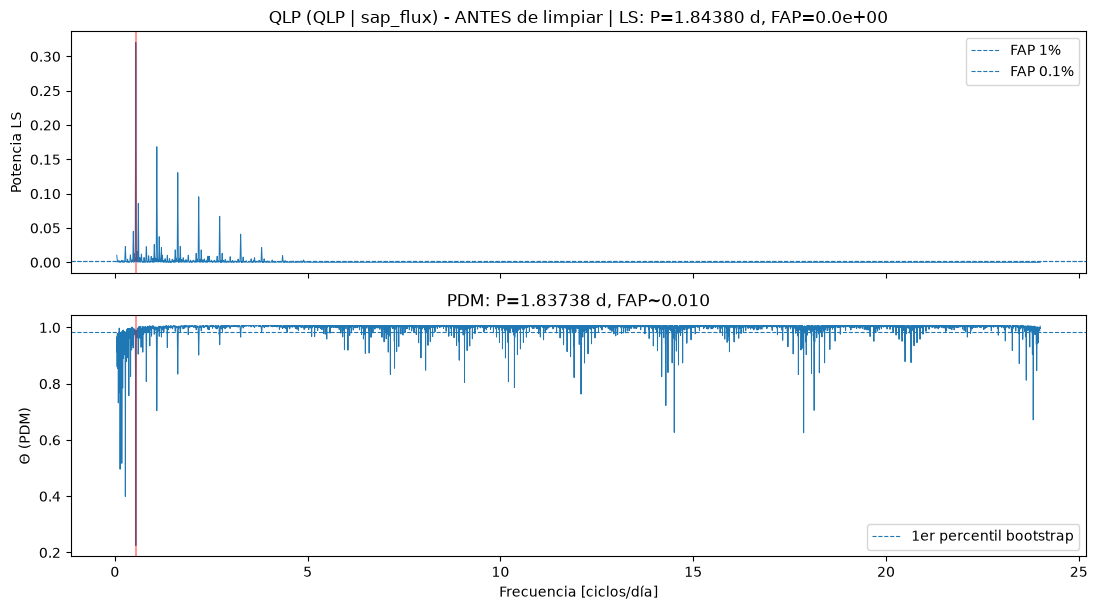


[QLP] Periodo PDM fino inicial: P = 1.843799 d | T0 = 3775.37257

O-C: 37 eclipses medidos (17 primarios, 20 secundarios), 15 discrepantes
  P_OC = 1.839745 +- 0.000307 d   (P_PDM fino: 1.843799 d)
  dispersión del O-C (buenos) = 16.9 min
  descartado por O-C: secundario BTJD 3776.492, O-C = +247.2 min
  descartado por O-C: secundario BTJD 3779.745, O-C = -367.1 min
  descartado por O-C: secundario BTJD 3781.754, O-C = -123.3 min
  descartado por O-C: secundario BTJD 3791.243, O-C = +293.9 min
  descartado por O-C: secundario BTJD 3793.086, O-C = +299.8 min
  descartado por O-C: secundario BTJD 3796.473, O-C = -121.9 min
  descartado por O-C: secundario BTJD 3798.137, O-C = -374.7 min
  descartado por O-C: secundario BTJD 3800.015, O-C = -320.3 min
  descartado por O-C: secundario BTJD 3805.565, O-C = -275.8 min
  descartado por O-C: secundario BTJD 3807.506, O-C = -129.6 min
  descartado por O-C: secundario BTJD 3811.345, O-C = +99.4 min
  descartado por O-C: secundario BTJD 3818.852

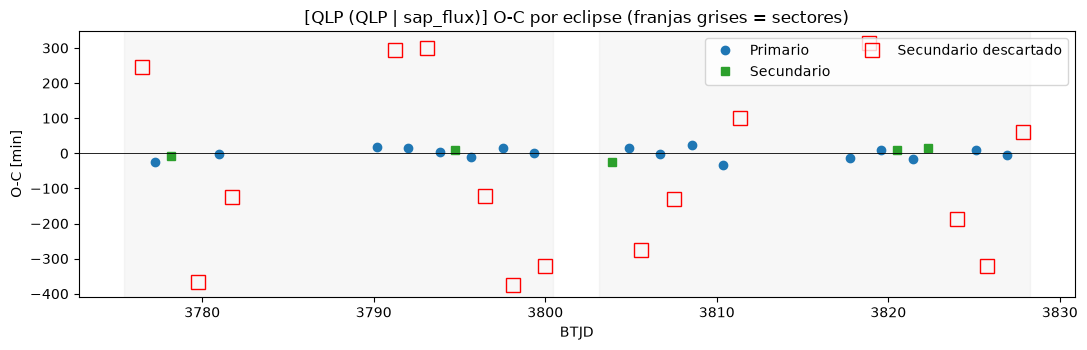

[QLP] Periodo adoptado para plegado y limpieza: P = 1.843799 d

[Análisis por Ciclo Orbital] Total ciclos: 24 | Ciclos descartados completos: 3
  Ciclo   0 (BTJD ~ 3776.10): DESCARTADO (RMS_eclipse=0.0783>0.0609)
  Ciclo   7 (BTJD ~ 3789.56): DESCARTADO (offset=-0.0154, RMS_ciclo=0.0245>0.0131)
  Ciclo  20 (BTJD ~ 3812.08): DESCARTADO (offset=-0.0166, RMS_ciclo=0.0343>0.0131)


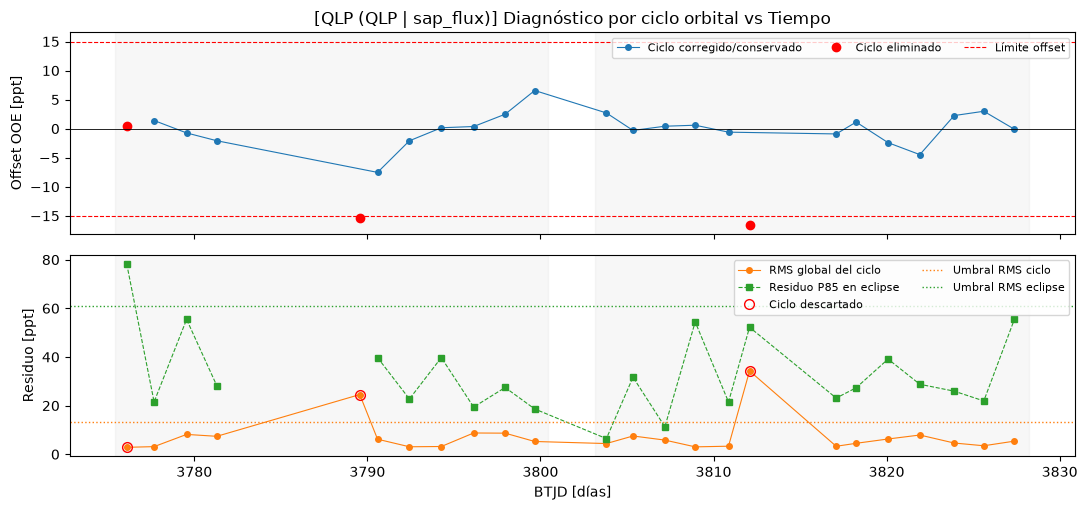

  iteración 1: 597 puntos fuera de plantilla (+597 en este paso; 0 en ventana de eclipse)
  iteración 2: 641 puntos fuera de plantilla (+44 en este paso; 0 en ventana de eclipse)
  iteración 3: 645 puntos fuera de plantilla (+5 en este paso; 0 en ventana de eclipse)
  iteración 4: 645 puntos fuera de plantilla (+0 en este paso; 0 en ventana de eclipse)

================ RESUMEN DE LIMPIEZA [QLP (QLP | sap_flux)] ================
Total puntos iniciales (tras reducción base): 15939
  - Removidos por ciclo orbital anómalo : 872 (5.47 %)
  - Removidos por eclipse desfasado O-C : 2209 (13.86 %)
  - Removidos por plantilla de fase     : 645 (4.05 %)
Total puntos removidos                  : 3726 de 15939 (23.38 %)
  * Sector 91: 2088 removidos de 7436 (28.08 %)
  * Sector 92: 1638 removidos de 8503 (19.26 %)
Periodo orbital final                   : P = 1.843799 d | T0 = 3775.372570 BTJD

[QLP] Exportado: TIC117831881_QLP_S91_S92_limpia.fits | puntos_removidos_TIC117831881_QLP.txt


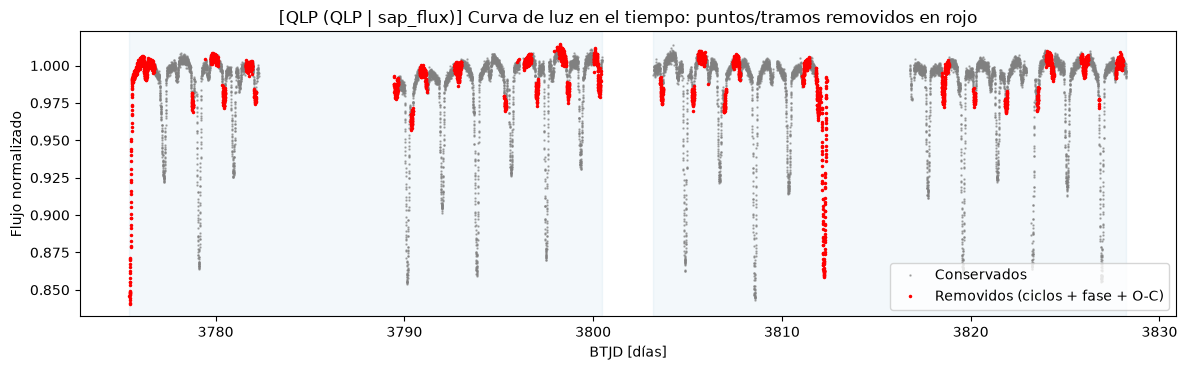

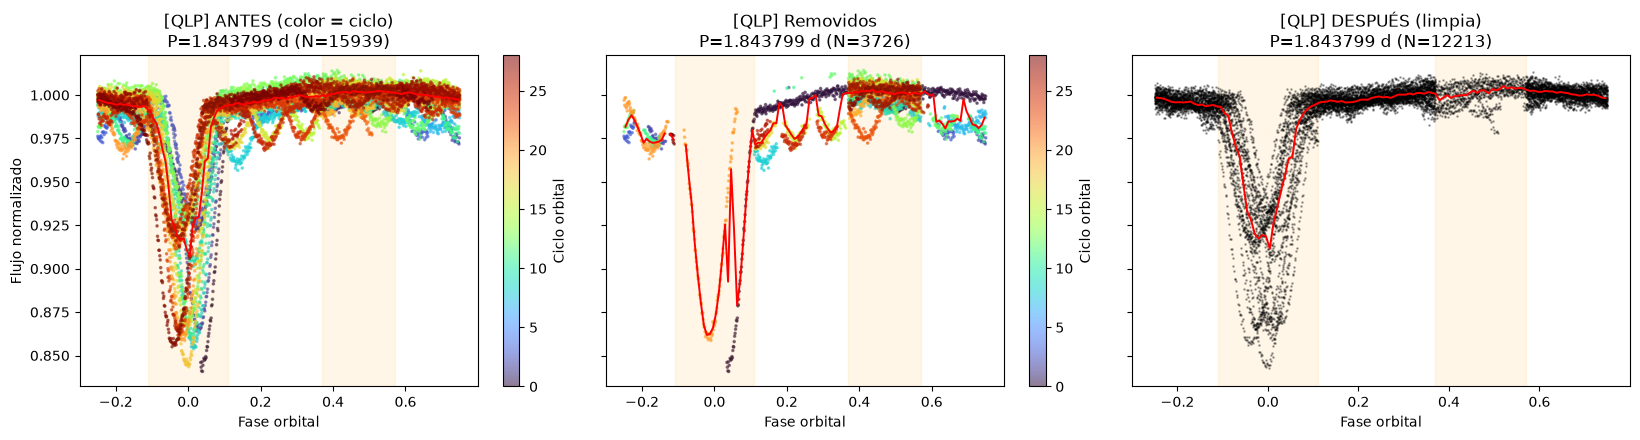


[QLP (QLP | sap_flux) - DESPUÉS de limpiar] N=12213, baseline=51.49 d
  LS : P = 0.919840 d (2xP = 1.839680 d), potencia = 0.3321, FAP = 0.00e+00
  PDM: P = 1.840523 d (2xP = 3.681046 d), theta_min = 0.2093, FAP ~ 0.010 (mínimo resoluble 1/101)


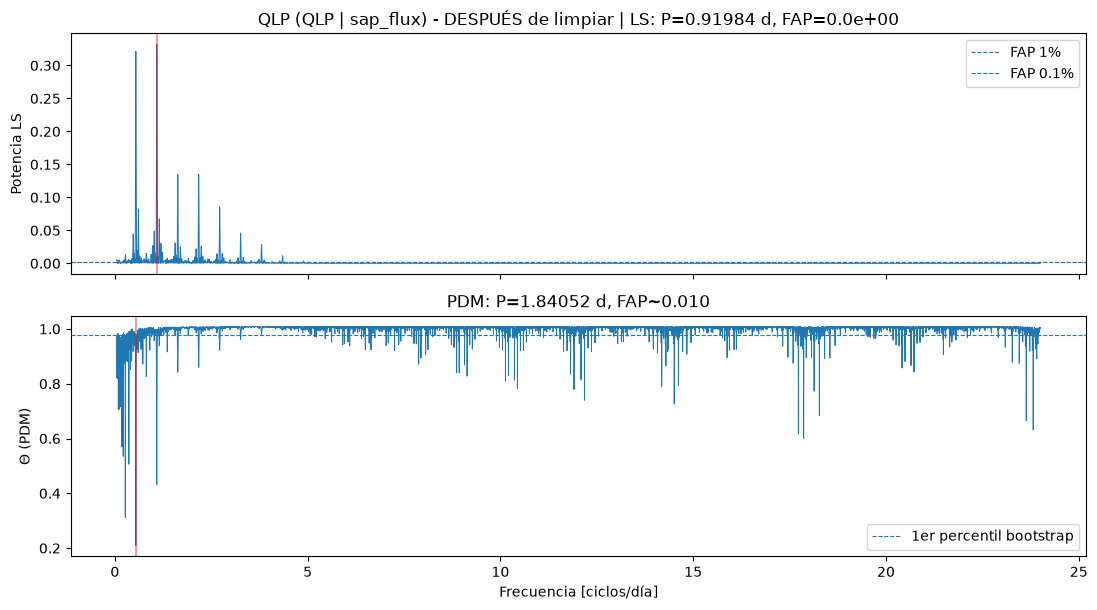

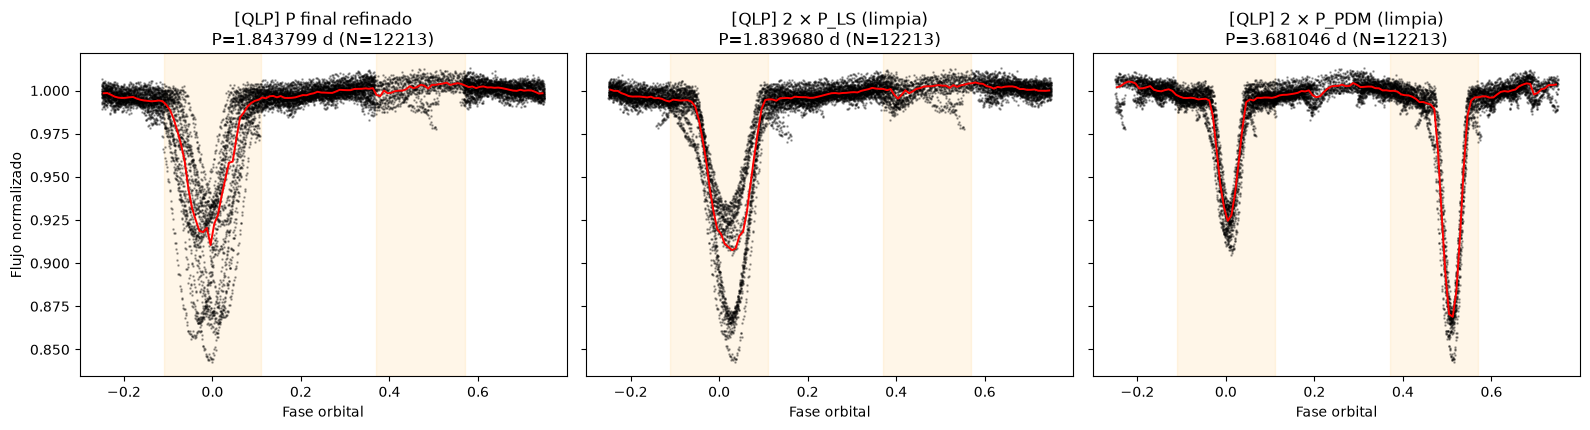


[QLP / PREWHITENING] T=51.487 d, Rayleigh=0.019422 c/d, Nyquist efectiva heuristica=215.98 c/d, Fmax usada=24.00 c/d
[QLP / PREWHITENING] T0=3777.222238 BTJD (autodetectado), eclipses=plantilla
  Modelo P: f0=0.543171989 +/- 1.25e-05 c/d (formal), P0=1.841037497 d, Nterm=44, BIC=-106817.7
  Modelo 2P: f0=0.271585995 +/- 5.68e-06 c/d (formal), P0=3.682074994 d, Nterm=88, BIC=-116798.7
  --> Modelo elegido: 2P
  ADVERTENCIA: error de frecuencia FORMAL; no incorpora ruido rojo, O-C ni incertidumbre de normalizacion.
  Desplazamientos destacados de la ventana: [0.068] c/d
     PW 01: f=1.2067228 c/d, P=0.8286907 d, A=3.981 ppt, S/N=7.40, FAP=0.00e+00 [independiente]
     PW 02: f=2.4132433 c/d, P=0.4143801 d, A=3.103 ppt, S/N=5.32, FAP=6.10e-287 [independiente]
     PW 03: f=2.1726880 c/d, P=0.4602594 d, A=0.189 ppt, S/N=4.90, FAP=3.33e-175 [orbital/armónico]
     PW 04: f=3.2590319 c/d, P=0.3068396 d, A=0.180 ppt, S/N=5.11, FAP=6.28e-172 [orbital/armónico]


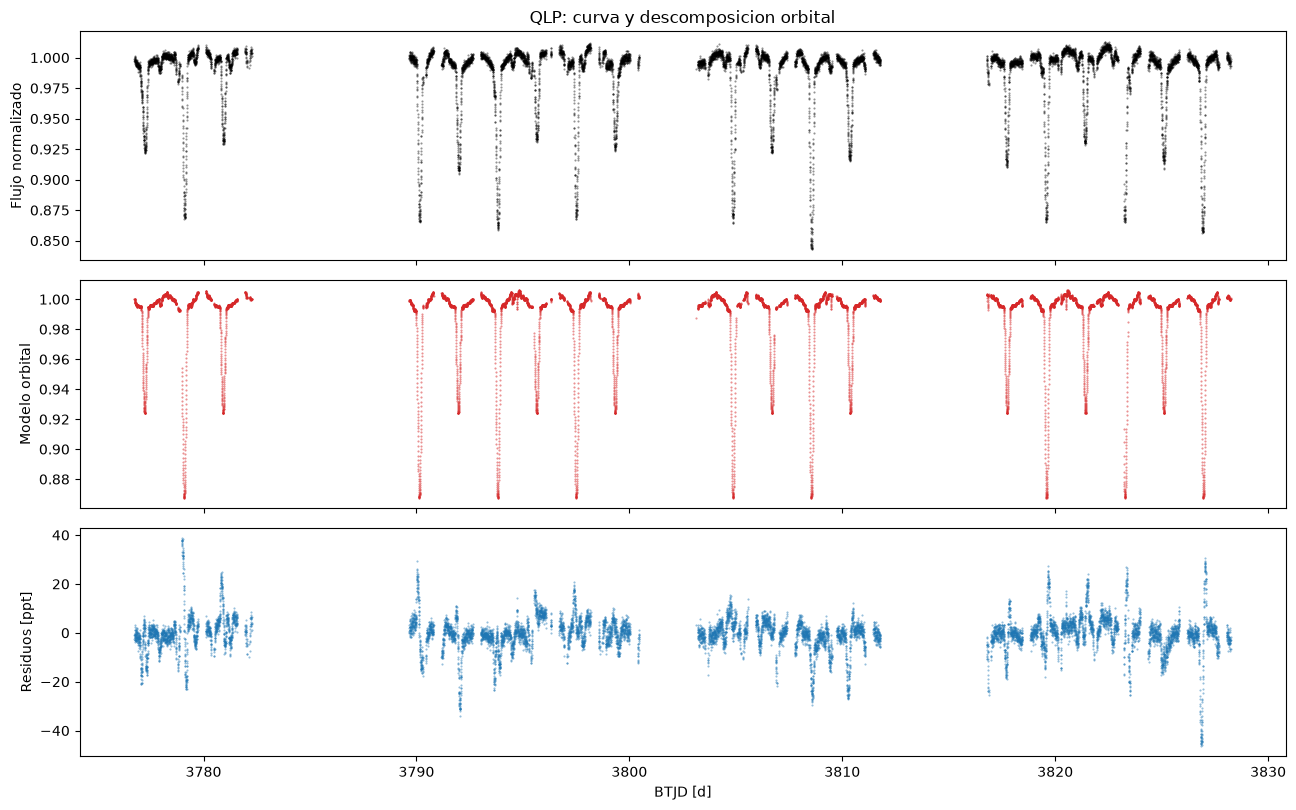

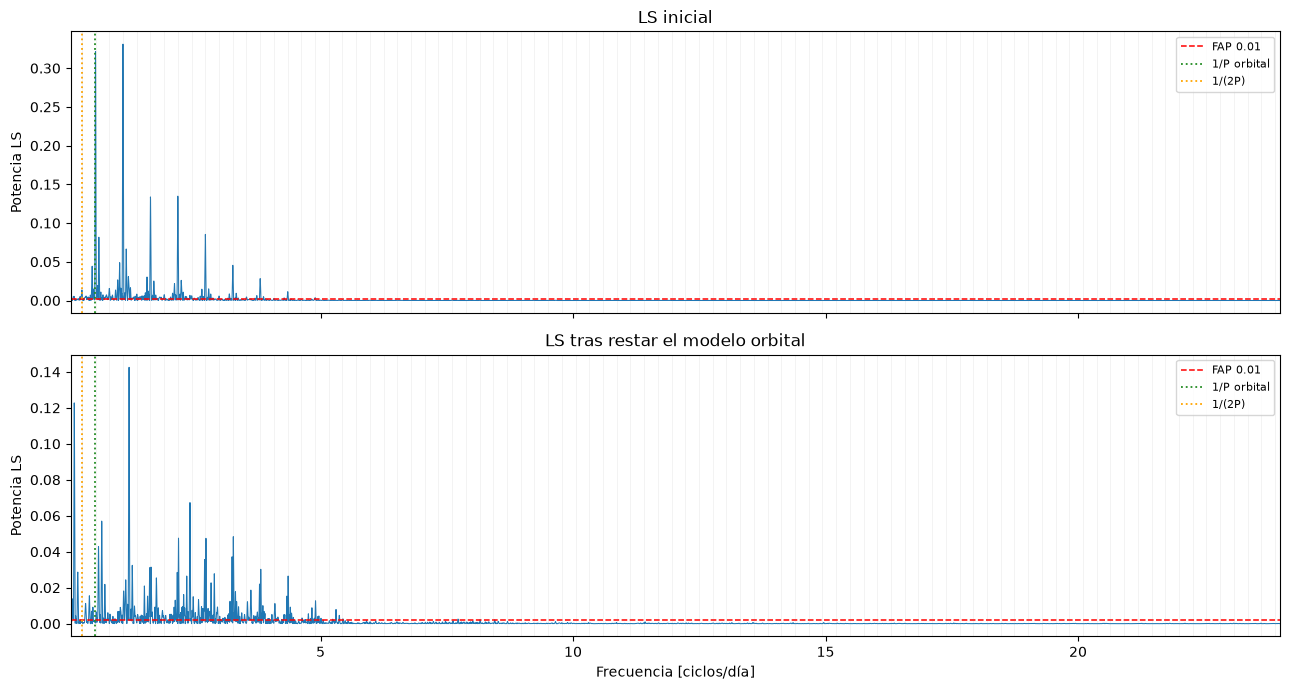

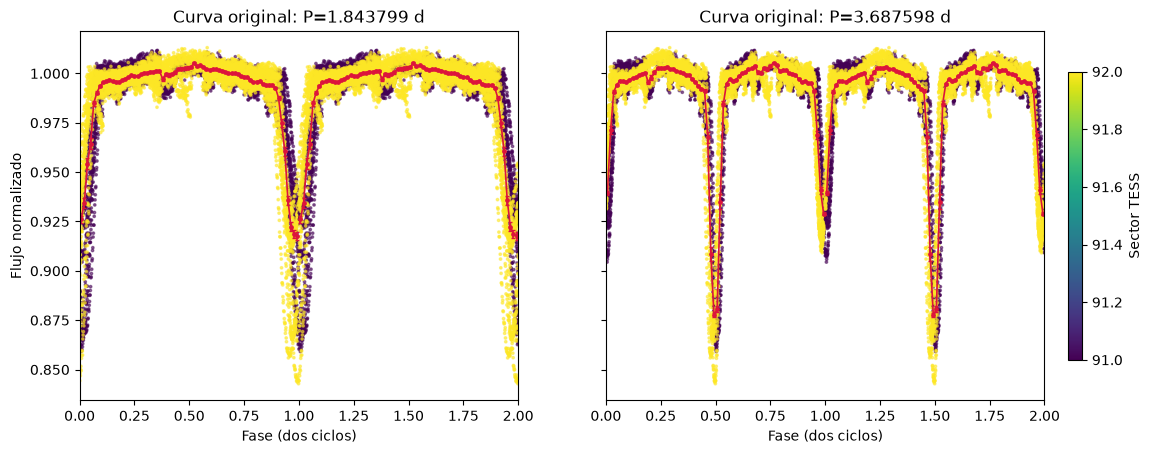

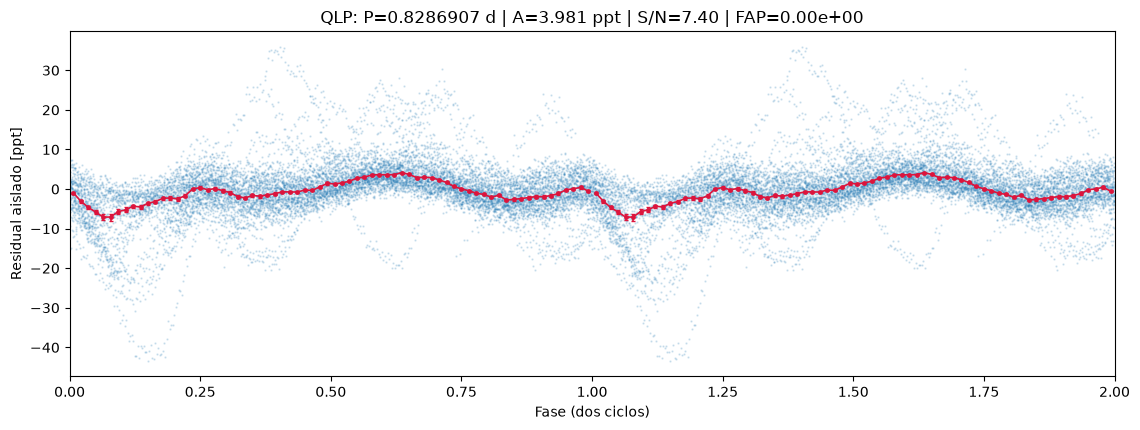

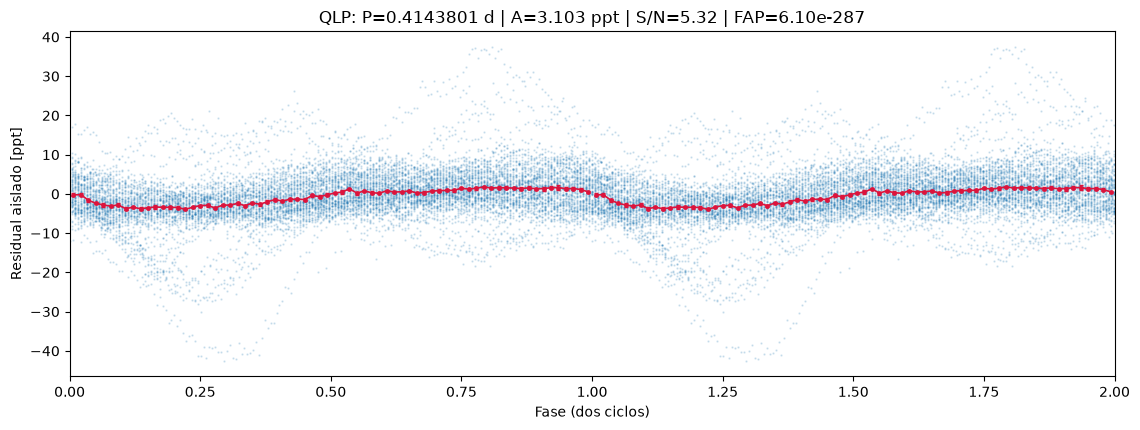

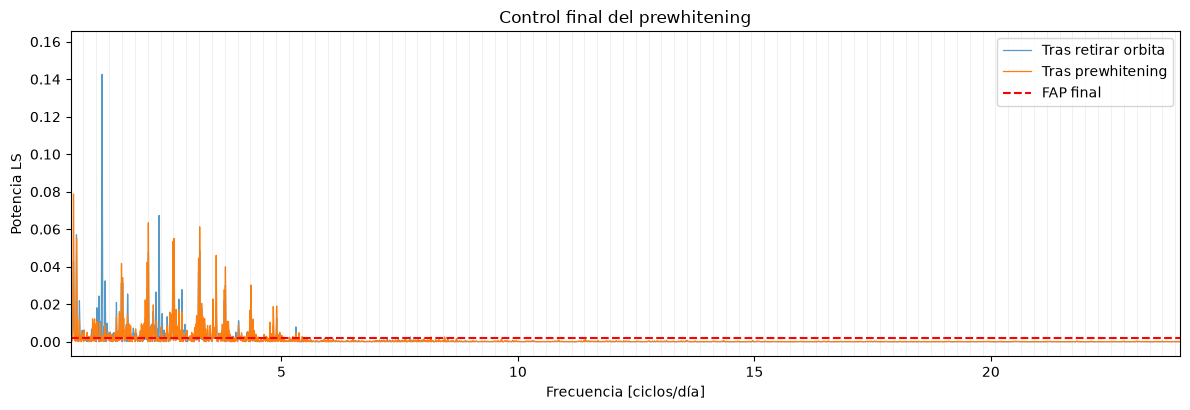

  AVISO: 10 armonicos nominales aun superan el umbral LS tras la sustraccion orbital; probar mas armonicos, corregir P/T0, o estudiar TTV, eclipses y efectos instrumentales.
  Ordenes afectados: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  Senales cortas independientes: 2
  Archivos guardados en: C:\Users\darkm\Desktop\archivos_Investigación\Investigacion\resultados_prewhitening\TIC117831881\QLP

########################################################################
### EJECUTANDO PIPELINE: SPOC
########################################################################
[SPOC] Sin resultados en MAST para author='SPOC'.
[SPOC] author='TESS-SPOC' existe en otros sectores, pero no en ['TESS Sector 91', 'TESS Sector 92'].
[SPOC] AVISO: No se encontraron datos para autores ['SPOC', 'TESS-SPOC'] en ['TESS Sector 91', 'TESS Sector 92'].


In [12]:
# ======================= EJECUCIÓN PRINCIPAL =======================

if __name__ == "__main__":
    inspeccionar_disponibilidad()
    resultados = [ejecutar_pipeline(cfg) for cfg in PIPELINES]
    comparar_pipelines(resultados)
